# VERIDYCT · Understanding the lexicon
## An evidence-first structural, linguistic, and experimental audit

**Dataset:** `data/lexicon.json` · **Scope:** lexicon only · **Companion study:** practice sentences, to be analysed separately.

This notebook asks how the published vocabulary constrains extraction, reasoning, synthetic-data design,
and evaluation. It is deliberately more than a descriptive dashboard: it includes complete inventories,
ambiguity audits, structural graphs, reproducible matching experiments, proposed test strata, and reusable exports.

**Read the evidence labels:** **Measured** means computed from the JSON. **Contract** means a rule in the local
challenge documents. **Hypothesis** means an analyst proposal that still needs validation against labelled sentences.
An allowed attribute is not a known value; a declared event is not a known event date; shared vocabulary is not a factual relationship.

The [reference analysis](https://mihaipriboi.github.io/heart_attack_analysis/) motivates the progression from
descriptive statistics to experiments and implications. Here there is no outcome column, so supervised truth
classification, ROC curves, and numerical correlations between arbitrarily encoded names would be inappropriate.
Our experiments measure **entity mention extraction on explicitly synthetic examples**, not truth-checking accuracy.

## Navigation

1. [Questions, boundaries, and reproducibility](#questions)
2. [Load and validate the raw JSON](#validation)
3. [Relational views and inventory](#inventory)
4. [Breadth, concentration, and missingness](#breadth)
5. [Alias coverage and normalisation](#aliases)
6. [Nested names and lexical ambiguity](#overlap)
7. [Attribute reuse and vocabulary](#attributes)
8. [Subject–attribute structure](#structure)
9. [Similarity and candidate families](#similarity)
10. [Attribute co-occurrence](#cooccurrence)
11. [Events and temporal blind spots](#events)
12. [Value-type hypotheses and relation candidates](#types)
13. [Claim-generation opportunities and limits](#claims)
14. [Executable entity-matching experiments](#experiments)
15. [Synthetic-data and evaluation design](#evaluation)
16. [Prioritised findings and open questions](#findings)
17. [Exports and integrity checks](#exports)
18. [Complete subject and attribute atlas](#atlas)

<a id="questions"></a>
## 1. Questions, boundaries, and reproducibility

| Question | Evidence available here | What must wait for practice data |
|---|---|---|
| What entities and attributes are legal? | Explicit declarations | Actual sentence coverage |
| How can a name be written? | Canonical names and published aliases | Undeclared paraphrases, pronouns, contextual references |
| Which names overlap or collide? | Exact and normalised surface forms | Real-world frequency of ambiguity in the fictional corpus |
| Which entities share structure? | Attribute set intersections | Shared values, inheritance, or ownership |
| What might a value's type be? | Attribute-name hints only | Kind, unit, currency, billing period, cardinality |
| Which claims can be produced? | Legal slots and event names | Truth, provenance, temporal validity, novelty |
| Which examples should we create? | Structural stress cases | Truth-labelled examples grounded in observed evidence |

This is a **census of the supplied lexicon**, not a random sample. Distribution summaries are descriptive;
we do not attach population p-values or infer language frequencies from one occurrence per declared spelling.

Run from the repository root or `analysis/`. Install the adjacent `requirements-lexicon.txt` into your own
environment, then open `01_lexicon_analysis.ipynb` and **Restart Kernel → Run All**.
The notebook needs no network, reads no practice CSV, preserves the source JSON, and writes only beneath
`analysis/lexicon_outputs/`. Figures are saved as PNG and PDF; tables as CSV; machine-readable indexes as JSON.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
import hashlib, importlib.metadata, json, math, os, platform, re, sys, unicodedata

def locate_root(start):
    for candidate in [start, *start.parents]:
        if (candidate / "data/lexicon.json").is_file():
            return candidate
    raise FileNotFoundError("Start Jupyter in the repository root or analysis/ directory.")

ROOT = locate_root(Path.cwd())
OUTPUT = ROOT / "analysis/lexicon_outputs"
FIGURES = OUTPUT / "figures"
TABLES = OUTPUT / "tables"
for directory in [OUTPUT, FIGURES, TABLES]:
    directory.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUTPUT / ".matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 180, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 75)

def show_all(frame):
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
        display(frame)

figure_names = []
def finish_figure(name):
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    figure_names.append(name)
    plt.show()
    plt.close(fig)

raw_path = ROOT / "data/lexicon.json"
raw_bytes = raw_path.read_bytes()
source_sha256 = hashlib.sha256(raw_bytes).hexdigest()
environment = {p: importlib.metadata.version(p) for p in
               ["pandas", "numpy", "matplotlib", "seaborn", "networkx", "nbformat", "nbclient", "nbconvert", "ipykernel"]}
display(pd.Series({"Python": platform.python_version(), "source bytes": len(raw_bytes),
                   "SHA-256": source_sha256, **environment}, name="reproducibility"))

Python                                                                    3.14.8
source bytes                                                               20209
SHA-256         d0fd5e9bdc6b33ad3ec160001f50e00e7f8bf2b25a92779022f893db7c3d5507
pandas                                                                     2.3.3
numpy                                                                      2.5.4
matplotlib                                                                3.11.2
seaborn                                                                   0.13.2
networkx                                                                     3.7
nbformat                                                                  5.11.1
nbclient                                                                  0.11.0
nbconvert                                                                 7.17.2
ipykernel                                                                  7.4.0
Name: reproducibility, dtype

<a id="validation"></a>
## 2. Load and validate the raw JSON

**Method.** Check JSON duplicate keys before normalisation, required fields and types, empty strings,
duplicate canonical names, duplicate attributes, attribute syntax, and event references. We keep raw aliases
intact: duplicates after normalisation are findings, not permission to rewrite the source.

An empty alias list means **no alternate spelling supplied**, not an invalid entity. An absent value field
is by design: this file declares vocabulary, not the state of the universe.

In [2]:
duplicate_json_keys = []
def audit_pairs(pairs):
    result = {}
    for key, value in pairs:
        if key in result:
            duplicate_json_keys.append(key)
        result[key] = value
    return result

lexicon = json.loads(raw_bytes.decode("utf-8"), object_pairs_hook=audit_pairs)
assert isinstance(lexicon, dict), "Root must be an object"
assert set(lexicon) == {"subjects", "events"}, "Unexpected root fields; inspect before proceeding"
assert isinstance(lexicon["subjects"], list) and isinstance(lexicon["events"], list)
checks = []
def check(name, ok, detail):
    checks.append({"check": name, "passes": bool(ok), "detail": detail})

check("No duplicate JSON keys", not duplicate_json_keys, str(duplicate_json_keys))
for i, subject in enumerate(lexicon["subjects"]):
    assert isinstance(subject, dict), f"Subject {i}: expected object"
    assert set(subject) == {"name", "aliases", "attributes"}, f"Subject {i}: unexpected fields"
    assert isinstance(subject["name"], str) and subject["name"].strip(), f"Subject {i}: invalid name"
    for field in ["aliases", "attributes"]:
        assert isinstance(subject[field], list), f"Subject {i}: {field} must be a list"
        assert all(isinstance(v, str) and v.strip() for v in subject[field]), f"Subject {i}: invalid {field}"
assert all(isinstance(e, str) and e.strip() for e in lexicon["events"])
names_raw = [s["name"] for s in lexicon["subjects"]]
check("Canonical names unique", len(names_raw) == len(set(names_raw)), "Exact spelling")
check("Event declarations unique", len(lexicon["events"]) == len(set(lexicon["events"])), "Exact spelling")
check("Events reference canonical subjects", set(lexicon["events"]) <= set(names_raw),
      str(sorted(set(lexicon["events"]) - set(names_raw))))
check("Each subject has at least one attribute", all(s["attributes"] for s in lexicon["subjects"]), "Nonempty lists")
check("No exact duplicate attributes per subject", all(len(s["attributes"]) == len(set(s["attributes"])) for s in lexicon["subjects"]), "Before deduplication")
check("Attributes satisfy contract identifier syntax", all(re.fullmatch(r"[a-z][a-z0-9_]*", a)
      for s in lexicon["subjects"] for a in s["attributes"]), "[a-z][a-z0-9_]*")
all_strings = names_raw + lexicon["events"] + [v for s in lexicon["subjects"] for field in ["aliases", "attributes"] for v in s[field]]
check("No leading or trailing whitespace", all(v == v.strip() for v in all_strings), "All declared strings")
check("Canonical names fit entry schema length", all(len(n) <= 120 for n in names_raw), "Maximum 120 characters")
validation = pd.DataFrame(checks)
display(validation)
assert validation["passes"].all(), "Resolve structural validation failures before interpreting analyses"
display(Markdown("**Measured:** all structural checks pass. Normalisation redundancy is audited separately below."))

,check,passes,detail
0,No duplicate JSON keys,True,[]
1,Canonical names unique,True,Exact spelling
2,Event declarations unique,True,Exact spelling
3,Events reference canonical subjects,True,[]
4,Each subject has at least one attribute,True,Nonempty lists
5,No exact duplicate attributes per subject,True,Before deduplication
6,Attributes satisfy contract identifier syntax,True,[a-z][a-z0-9_]*
7,No leading or trailing whitespace,True,All declared strings
8,Canonical names fit entry schema length,True,Maximum 120 characters


**Measured:** all structural checks pass. Normalisation redundancy is audited separately below.

<a id="inventory"></a>
## 3. Relational views and inventory

We build three lossless views: one row per subject, one row per declared spelling (including aliases),
and one row per allowed `(subject, attribute)` pair. Events are an explicit membership flag.
The key for a future fact is **the pair**, not the attribute alone.

In [3]:
event_names = set(lexicon["events"])
subjects = pd.DataFrame([{
    "subject": s["name"], "aliases": s["aliases"], "attributes": s["attributes"],
    "alias_count": len(s["aliases"]), "attribute_count": len(s["attributes"]),
    "is_event": s["name"] in event_names, "name_characters": len(s["name"]),
    "name_tokens": len(s["name"].split())
} for s in lexicon["subjects"]])
surfaces = pd.DataFrame([{"subject": s["name"], "surface": value, "source": source}
    for s in lexicon["subjects"]
    for source, values in [("canonical", [s["name"]]), ("alias", s["aliases"])]
    for value in values])
slots = pd.DataFrame([{"subject": s["name"], "attribute": a}
                     for s in lexicon["subjects"] for a in s["attributes"]])
subject_attributes = {s["name"]: set(s["attributes"]) for s in lexicon["subjects"]}
attribute_subjects = slots.groupby("attribute")["subject"].agg(lambda x: sorted(set(x))).to_dict()
N = len(subjects)
attribute_counts = slots.groupby("attribute").size().sort_values(ascending=False)
summary = pd.DataFrame([
    ("Subjects", N), ("Event subjects", int(subjects.is_event.sum())),
    ("Declared aliases", len(surfaces.query("source == 'alias'"))),
    ("All declared spellings", len(surfaces)), ("Subject–attribute slots", len(slots)),
    ("Distinct attributes", len(attribute_counts)),
    ("Attributes on one subject only", int((attribute_counts == 1).sum())),
    ("Subjects with no aliases", int((subjects.alias_count == 0).sum()))
], columns=["measure", "count"])
display(summary)
display(subjects.drop(columns="attributes").sort_values("attribute_count", ascending=False).head(12))
assert not slots.duplicated().any()
assert len(slots) == subjects.attribute_count.sum()

,measure,count
0,Subjects,62
1,Event subjects,13
2,Declared aliases,48
3,All declared spellings,110
4,Subject–attribute slots,514
5,Distinct attributes,321
6,Attributes on one subject only,241
7,Subjects with no aliases,18


,subject,aliases,alias_count,attribute_count,is_event,name_characters,name_tokens
6,Hooly,"[Hooly AI, Hooly Inc.]",2,32,False,5,1
22,Hooly Gemini,[Gemini],1,30,False,12,2
16,Hooly Cloud,[],0,22,False,11,2
29,Hooly Maps,[Maps],1,16,False,10,2
36,Hooly Pixel 10,[Pixel 10],1,16,False,14,3
24,Hooly Hiring Programme,[Hooly Hiring],1,15,False,22,3
46,Hooly Search,[Search],1,14,False,12,2
32,Hooly Photos,[Photos],1,14,False,12,2
30,Hooly Maps Day,[Maps Day],1,14,True,14,3
15,Hooly Chrome,[Chrome],1,14,False,12,2


<a id="breadth"></a>
## 4. Breadth, concentration, and missingness

Attribute count measures **schema breadth**, not the number of known facts, corpus mentions, business importance,
or difficulty. A subject with one attribute can be hard to recognise; one with many attributes can have simple sentences.
We report all subjects and a Lorenz curve to show where the schema is concentrated.

,attribute_count,alias_count,name_characters,name_tokens
count,62.00,62.00,62.00,62.00
mean,8.29,0.77,14.68,2.53
std,6.42,0.56,4.49,0.82
min,1.00,0.00,5.00,1.00
25%,3.00,0.00,12.00,2.00
50%,8.00,1.00,14.00,2.00
75%,11.00,1.00,17.00,3.00
max,32.00,2.00,27.00,4.00


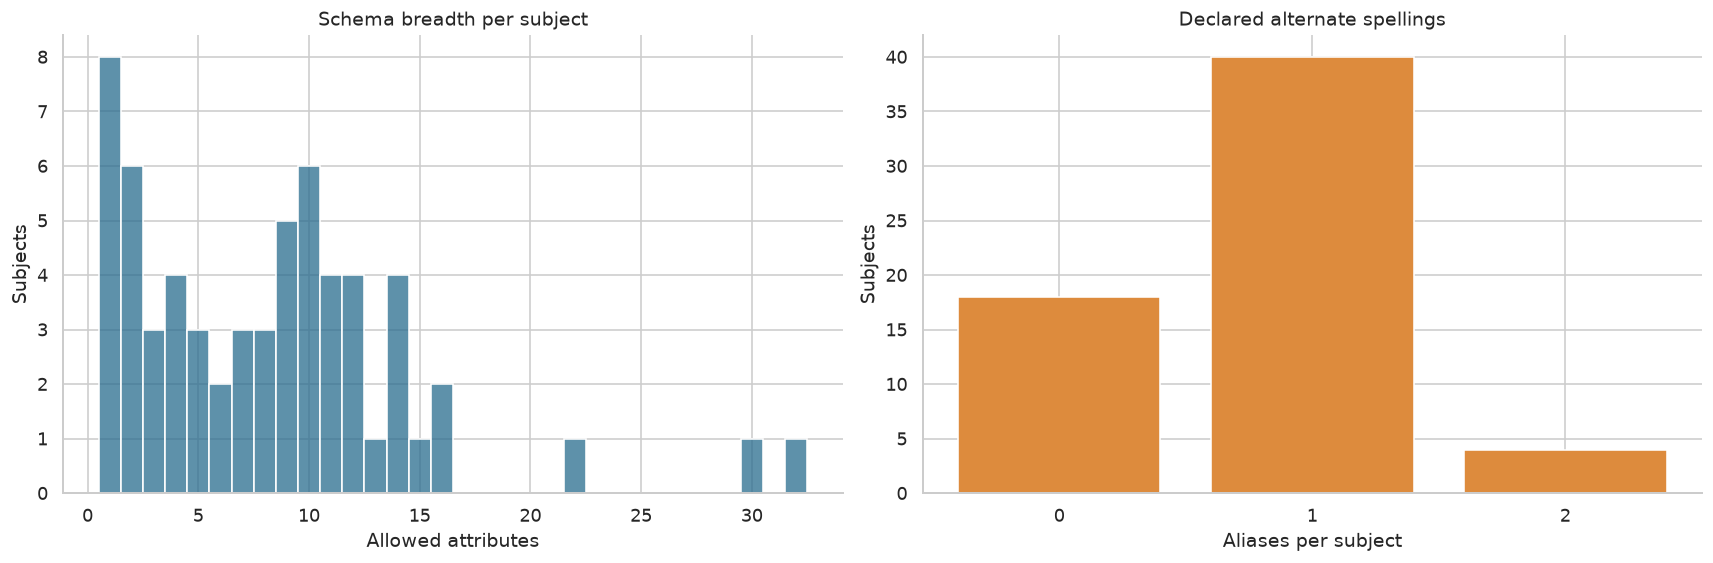

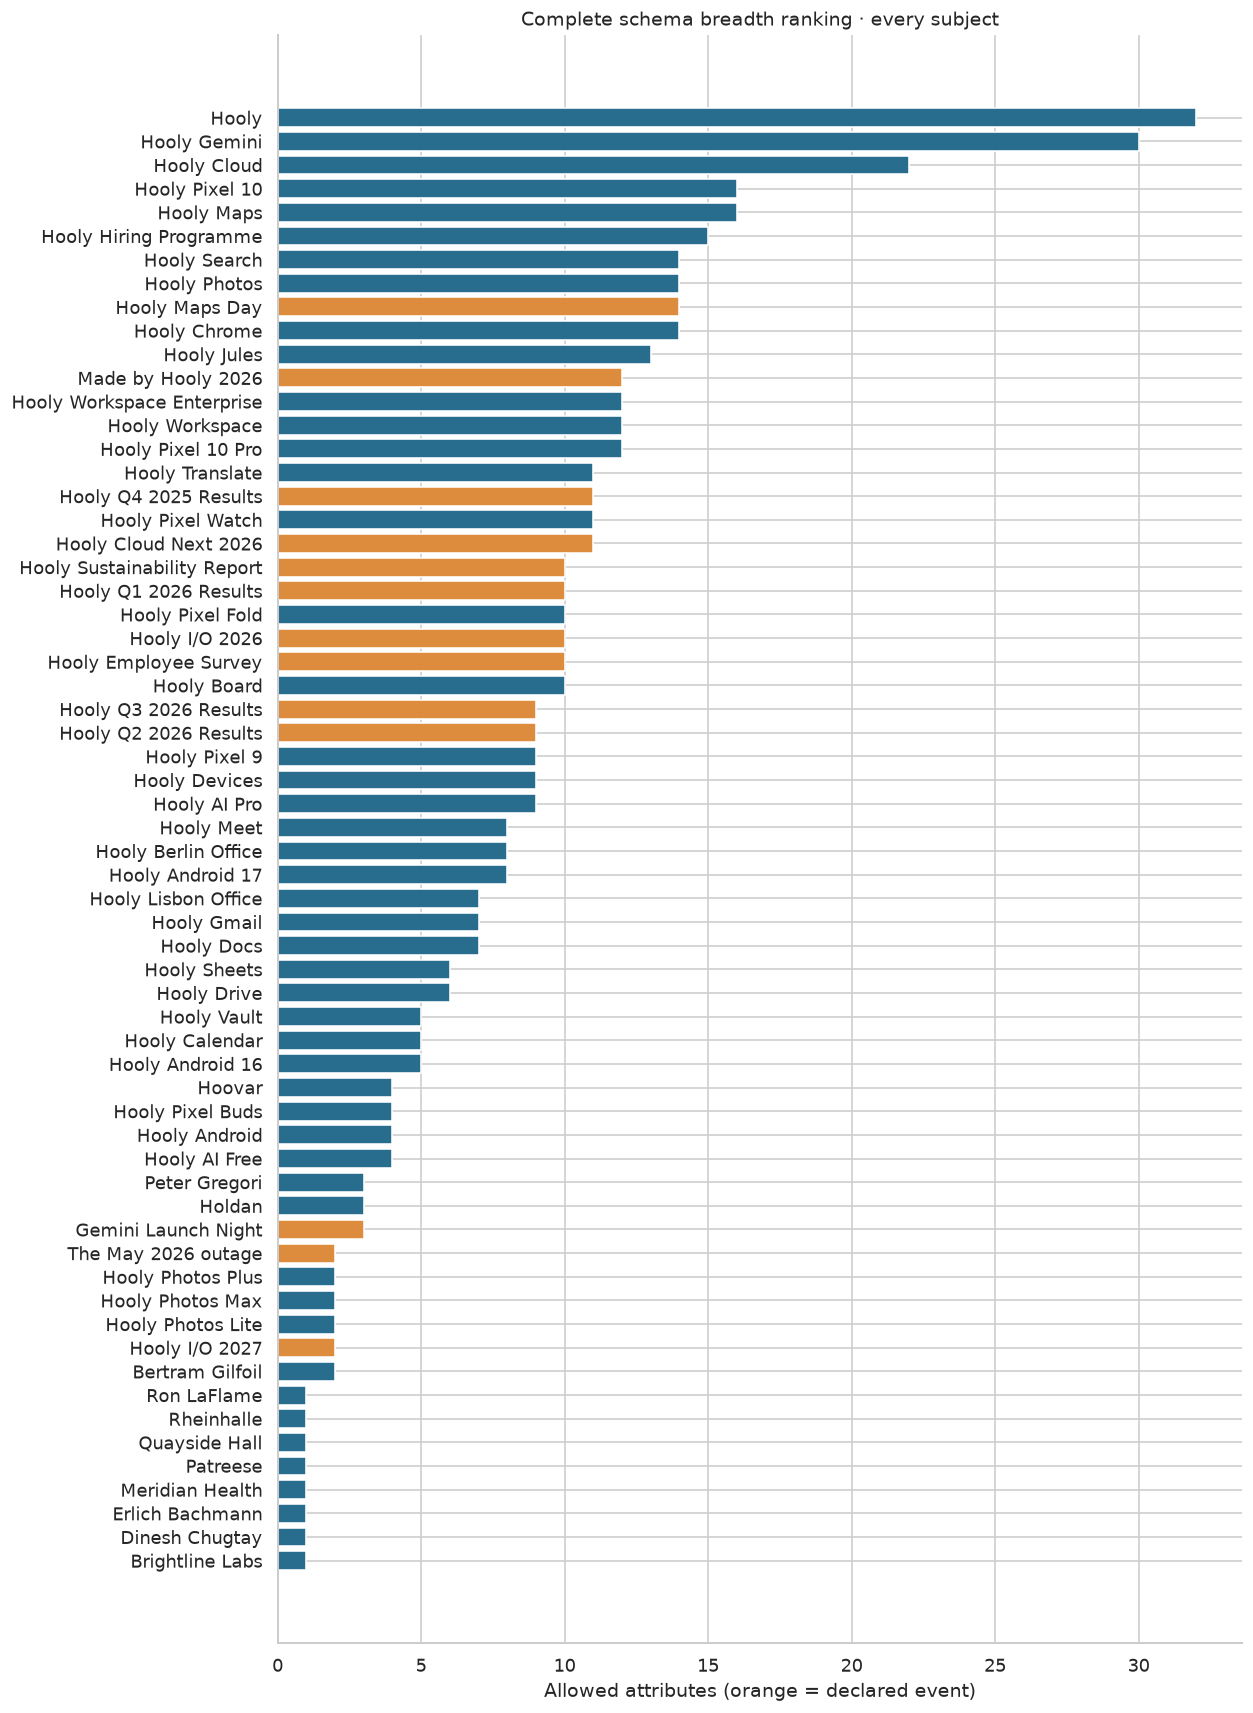

In [4]:
display(subjects[["attribute_count", "alias_count", "name_characters", "name_tokens"]].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=subjects, x="attribute_count", discrete=True, ax=axes[0], color="#286c8e")
axes[0].set(title="Schema breadth per subject", xlabel="Allowed attributes", ylabel="Subjects")
alias_distribution = subjects.alias_count.value_counts().sort_index()
axes[1].bar(alias_distribution.index, alias_distribution.values, color="#dd8b3d")
axes[1].set(title="Declared alternate spellings", xlabel="Aliases per subject", ylabel="Subjects",
            xticks=alias_distribution.index)
finish_figure("01_schema_and_alias_distributions")

ordered = subjects.sort_values(["attribute_count", "subject"])
plt.figure(figsize=(11, 15))
plt.barh(ordered.subject, ordered.attribute_count,
         color=["#dd8b3d" if x else "#286c8e" for x in ordered.is_event])
plt.xlabel("Allowed attributes (orange = declared event)")
plt.title("Complete schema breadth ranking · every subject")
finish_figure("02_all_subject_breadth")

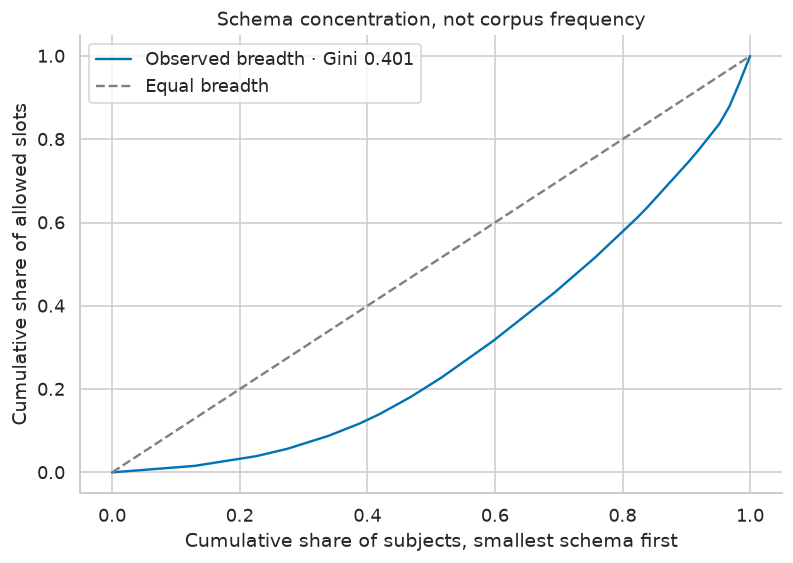

**Measured:** the five widest schemas contain **22.6%** of slots. Median breadth is **8** attributes. Do not remove high-breadth subjects as statistical outliers; they are valid parts of the task.

,audit,count,interpretation
0,Alias list empty,18,Valid: no alternate spelling declared
1,Attribute list empty,0,Would prevent structured claims
2,Fact values present,0,Not a field in this dataset
3,Validity intervals present,0,Not a field in this dataset
4,Explicit entity types present,0,Not a field in this dataset
5,Units/currencies/billing periods present,0,Not a field in this dataset


In [5]:
breadth = np.sort(subjects.attribute_count.to_numpy())
lorenz_x = np.arange(N + 1) / N
lorenz_y = np.r_[0, np.cumsum(breadth) / breadth.sum()]
gini = float((2 * np.sum(np.arange(1, N + 1) * breadth) / (N * breadth.sum())) - (N + 1) / N)
top5_share = subjects.nlargest(5, "attribute_count").attribute_count.sum() / len(slots)
plt.figure(figsize=(7, 5))
plt.plot(lorenz_x, lorenz_y, label=f"Observed breadth · Gini {gini:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Equal breadth")
plt.xlabel("Cumulative share of subjects, smallest schema first")
plt.ylabel("Cumulative share of allowed slots")
plt.title("Schema concentration, not corpus frequency")
plt.legend()
finish_figure("03_schema_concentration")
display(Markdown(f"**Measured:** the five widest schemas contain **{top5_share:.1%}** of slots. "
                 f"Median breadth is **{subjects.attribute_count.median():g}** attributes. "
                 "Do not remove high-breadth subjects as statistical outliers; they are valid parts of the task."))
missingness = pd.DataFrame([
    ("Alias list empty", int((subjects.alias_count == 0).sum()), "Valid: no alternate spelling declared"),
    ("Attribute list empty", int((subjects.attribute_count == 0).sum()), "Would prevent structured claims"),
    ("Fact values present", 0, "Not a field in this dataset"),
    ("Validity intervals present", 0, "Not a field in this dataset"),
    ("Explicit entity types present", 0, "Not a field in this dataset"),
    ("Units/currencies/billing periods present", 0, "Not a field in this dataset")
], columns=["audit", "count", "interpretation"])
display(missingness)

<a id="aliases"></a>
## 5. Alias coverage and normalisation

We compare three normalisers rather than silently choosing one:

- **Case + whitespace:** Unicode NFKC, case folding, and collapsed spaces. NFKC is an implementation choice,
  not an extra alias rule supplied by the challenge.
- **Compact spaces:** additionally remove whitespace. The claim/value rules explicitly discuss flexible spacing;
  exact behaviour still needs end-to-end referee-compatible validation.
- **Aggressive alphanumeric:** also removes punctuation. This is a diagnostic stress test, **not** a proposed
  universal matching rule; punctuation can distinguish names and technical identifiers.

A repeated normalised spelling owned by one subject is redundancy. One owned by multiple subjects is a collision.

In [6]:
def normalise(value):
    return " ".join(unicodedata.normalize("NFKC", value).casefold().split())
def compact(value):
    return re.sub(r"\s+", "", normalise(value))
def alphanumeric(value):
    return "".join(c for c in normalise(value) if c.isalnum())

normalisers = {"normalised": normalise, "compact": compact, "alphanumeric": alphanumeric}
for column, fn in normalisers.items():
    surfaces[column] = surfaces.surface.map(fn)
normalisation_rows, redundancy_rows = [], []
for mode in normalisers:
    for key, group in surfaces.groupby(mode):
        if len(group) > 1:
            redundancy_rows.append({"mode": mode, "key": key, "rows": len(group),
                                    "owners": group.subject.nunique(),
                                    "subjects": sorted(group.subject.unique()),
                                    "spellings": group.surface.tolist()})
    owners = surfaces.groupby(mode).subject.nunique()
    normalisation_rows.append({"mode": mode, "unique_keys": surfaces[mode].nunique(),
                               "redundant_rows": len(surfaces) - surfaces[mode].nunique(),
                               "cross_subject_collision_keys": int((owners > 1).sum())})
normalisation_audit = pd.DataFrame(normalisation_rows)
redundancies = pd.DataFrame(redundancy_rows, columns=["mode", "key", "rows", "owners", "subjects", "spellings"])
display(normalisation_audit)
show_all(redundancies)
unique_surfaces = surfaces.drop_duplicates(["subject", "normalised"]).copy()
effective_aliases = unique_surfaces.groupby("subject").size().sub(1)
subjects["effective_alias_count"] = subjects.subject.map(effective_aliases)
display(subjects.loc[subjects.alias_count != subjects.effective_alias_count,
                     ["subject", "aliases", "alias_count", "effective_alias_count"]])

,mode,unique_keys,redundant_rows,cross_subject_collision_keys
0,normalised,109,1,0
1,compact,109,1,0
2,alphanumeric,109,1,0


,mode,key,rows,owners,subjects,spellings
0,normalised,devices division,2,1,[Hooly Devices],"[Devices division, devices division]"
1,compact,devicesdivision,2,1,[Hooly Devices],"[Devices division, devices division]"
2,alphanumeric,devicesdivision,2,1,[Hooly Devices],"[Devices division, devices division]"


,subject,aliases,alias_count,effective_alias_count
18,Hooly Devices,"[Devices division, devices division]",2,1


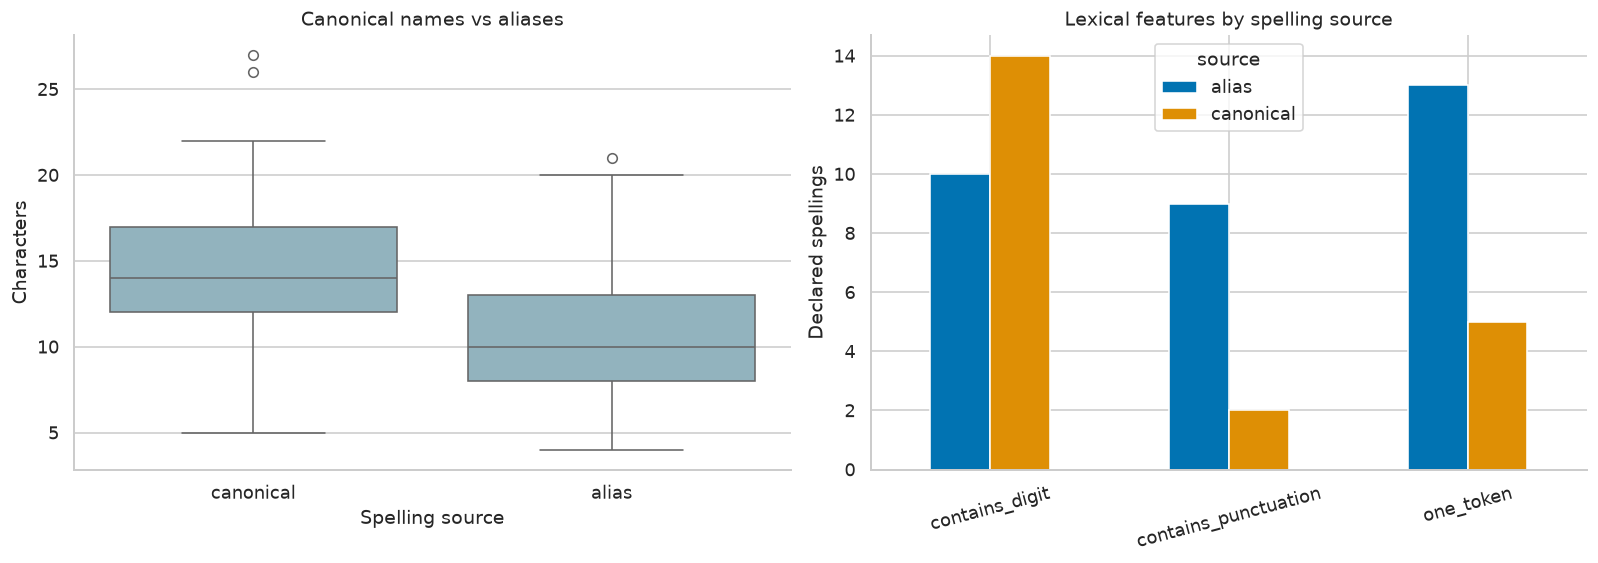

,subject,surface,source,tokens,contains_punctuation
2,Brightline Labs,Brightline,alias,1,False
7,Holdan,Holdan,canonical,1,False
8,Hooly,Hooly,canonical,1,False
10,Hooly,Hooly Inc.,alias,2,True
14,Hooly Android,Android,alias,1,False
22,Hooly Board,Hooly's board,alias,2,True
25,Hooly Chrome,Chrome,alias,1,False
38,Hooly Gemini,Gemini,alias,1,False
40,Hooly Gmail,Gmail,alias,1,False
43,Hooly I/O 2026,Hooly I/O 2026,canonical,3,True


**Interpretation:** short aliases improve recall but can match ordinary words. Examples such as `Search`, `Maps`, `Photos`, `Translate`, and `outage` need context in arbitrary prose. The lexicon alone cannot estimate how often those words are ambiguous.

In [7]:
surfaces["characters"] = surfaces.surface.str.len()
surfaces["tokens"] = surfaces.surface.str.split().str.len()
surfaces["contains_digit"] = surfaces.surface.str.contains(r"\d")
surfaces["contains_punctuation"] = surfaces.surface.map(lambda s: any(not c.isalnum() and not c.isspace() for c in s))
surfaces["one_token"] = surfaces.tokens.eq(1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=surfaces, x="source", y="characters", ax=axes[0], color="#8bb7c5")
axes[0].set(title="Canonical names vs aliases", xlabel="Spelling source", ylabel="Characters")
features = surfaces.groupby("source")[["contains_digit", "contains_punctuation", "one_token"]].sum().T
features.plot.bar(ax=axes[1], rot=15)
axes[1].set(title="Lexical features by spelling source", ylabel="Declared spellings", xlabel="")
finish_figure("04_surface_features")
display(surfaces.loc[surfaces.one_token | surfaces.contains_punctuation,
                     ["subject", "surface", "source", "tokens", "contains_punctuation"]])
display(Markdown("**Interpretation:** short aliases improve recall but can match ordinary words. "
                 "Examples such as `Search`, `Maps`, `Photos`, `Translate`, and `outage` need context in arbitrary prose. "
                 "The lexicon alone cannot estimate how often those words are ambiguous."))

<a id="overlap"></a>
## 6. Nested names and lexical ambiguity

**Contract:** a name inside another entity's longer name denotes the longer entity in that span.
`Hooly AI Pro` must not yield an additional company mention of `Hooly`.
We enumerate cross-subject containments with word boundaries, then compare them with raw substring matching.
Containment edges describe **strings**, never ownership or corporate relationships.

Raw substring surface pairs       84
Whole-word surface pairs          84
Distinct directed entity pairs    58
Subjects involved                 49
dtype: int64

,short_subject,short_surface,long_subject,long_surface,whole_word
0,Hooly Android,Hooly Android,Hooly Android 16,Hooly Android 16,True
1,Hooly Android,Hooly Android,Hooly Android 17,Hooly Android 17,True
2,Hooly Android,Android,Hooly Android 16,Hooly Android 16,True
3,Hooly Android,Android,Hooly Android 16,Android 16,True
4,Hooly Android,Android,Hooly Android 17,Hooly Android 17,True
5,Hooly Android,Android,Hooly Android 17,Android 17,True
6,Hooly Cloud,Hooly Cloud,Hooly Cloud Next 2026,Hooly Cloud Next 2026,True
7,Hooly Cloud,Hooly Cloud,Hooly Cloud Next 2026,Hooly Cloud Next,True
8,Hooly Gemini,Gemini,Gemini Launch Night,Gemini Launch Night,True
9,Hooly I/O 2026,Hooly I/O,Hooly I/O 2027,Hooly I/O 2027,True


,short_subject,short_surface,long_subject,long_surface,whole_word


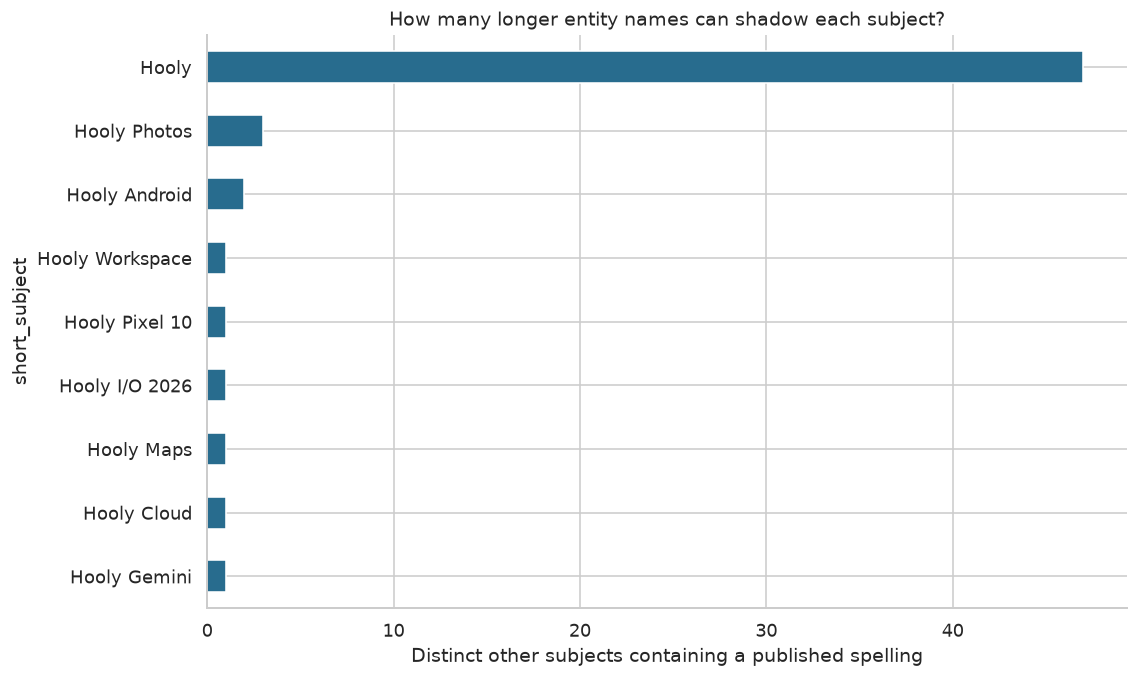

In [8]:
overlap_rows = []
for short in unique_surfaces.itertuples():
    boundary = re.compile(r"(?<!\w)" + re.escape(short.normalised) + r"(?!\w)")
    for long in unique_surfaces.itertuples():
        if short.subject == long.subject or short.normalised == long.normalised:
            continue
        if short.normalised in long.normalised:
            overlap_rows.append({"short_subject": short.subject, "short_surface": short.surface,
                                 "long_subject": long.subject, "long_surface": long.surface,
                                 "whole_word": bool(boundary.search(long.normalised))})
overlaps = pd.DataFrame(overlap_rows)
word_overlaps = overlaps[overlaps.whole_word].copy()
overlap_pairs = word_overlaps[["short_subject", "long_subject"]].drop_duplicates()
display(pd.Series({"Raw substring surface pairs": len(overlaps),
                   "Whole-word surface pairs": len(word_overlaps),
                   "Distinct directed entity pairs": len(overlap_pairs),
                   "Subjects involved": len(set(overlap_pairs.short_subject) | set(overlap_pairs.long_subject))}))
display(word_overlaps.loc[word_overlaps.short_subject != "Hooly"].reset_index(drop=True))
display(overlaps.loc[~overlaps.whole_word].reset_index(drop=True))
containment_counts = overlap_pairs.groupby("short_subject").size().sort_values()
plt.figure(figsize=(10, 6))
containment_counts.plot.barh(color="#286c8e")
plt.title("How many longer entity names can shadow each subject?")
plt.xlabel("Distinct other subjects containing a published spelling")
finish_figure("05_name_containment")

In [9]:
from difflib import SequenceMatcher
near_rows = []
for left, right in combinations(sorted(names_raw), 2):
    # Remove the shared brand prefix for this diagnostic only, never for canonicalisation.
    l = re.sub(r"^hooly\s+", "", normalise(left))
    r = re.sub(r"^hooly\s+", "", normalise(right))
    score = SequenceMatcher(None, l, r).ratio()
    if score >= 0.72:
        near_rows.append({"left": left, "right": right, "string_similarity": round(score, 3)})
near_names = pd.DataFrame(near_rows).sort_values("string_similarity", ascending=False)
show_all(near_names)
display(Markdown("**Hypothesis:** these pairs are useful hard-negative candidates for entity recognition. "
                 "String similarity is not permission to merge subjects. Android versions, Pixel variants, "
                 "annual events, and quarterly reports deliberately remain distinct."))

,left,right,string_similarity
12,Hooly Q2 2026 Results,Hooly Q3 2026 Results,0.933
9,Hooly Q1 2026 Results,Hooly Q2 2026 Results,0.933
10,Hooly Q1 2026 Results,Hooly Q3 2026 Results,0.933
2,Hooly Android 16,Hooly Android 17,0.900
4,Hooly I/O 2026,Hooly I/O 2027,0.875
11,Hooly Q1 2026 Results,Hooly Q4 2025 Results,0.867
13,Hooly Q2 2026 Results,Hooly Q4 2025 Results,0.867
14,Hooly Q3 2026 Results,Hooly Q4 2025 Results,0.867
0,Hooly Android,Hooly Android 16,0.824
1,Hooly Android,Hooly Android 17,0.824


**Hypothesis:** these pairs are useful hard-negative candidates for entity recognition. String similarity is not permission to merge subjects. Android versions, Pixel variants, annual events, and quarterly reports deliberately remain distinct.

<a id="attributes"></a>
## 7. Attribute reuse and vocabulary

How much extraction logic can be shared, and how much is specific to one entity?
We count **subjects per attribute**, not sentence frequency. A shared identifier such as `price` does not
guarantee compatible currencies or billing periods. Similar identifiers such as `users` and `active_users`
must remain separate unless evidence establishes equivalence.

,attribute,subject_count,subjects,tokens,token_count,is_singleton
0,launched,16,"[Hooly Calendar, Hooly Chrome, Hooly Cloud, Hooly Docs, Hooly Drive, Hooly Gemini, Hooly Gmail, ...",[launched],1,False
1,price,14,"[Hooly AI Free, Hooly AI Pro, Hooly Jules, Hooly Photos Lite, Hooly Photos Max, Hooly Photos Plu...",[price],1,False
2,version,8,"[Hooly Android, Hooly Calendar, Hooly Docs, Hooly Gemini, Hooly Jules, Hooly Maps, Hooly Photos,...",[version],1,False
3,customers,7,"[Hooly Cloud, Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025...",[customers],1,False
4,date,7,"[Gemini Launch Night, Hooly Cloud Next 2026, Hooly I/O 2026, Hooly I/O 2027, Hooly Maps Day, Mad...",[date],1,False
5,store_rating,6,"[Hooly Maps, Hooly Photos, Hooly Pixel 10, Hooly Pixel 9, Hooly Pixel Fold, Hooly Pixel Watch]","[store, rating]",2,False
6,city,6,"[Gemini Launch Night, Hooly Cloud Next 2026, Hooly I/O 2026, Hooly I/O 2027, Hooly Maps Day, Mad...",[city],1,False
7,released,6,"[Hooly Android 16, Hooly Pixel 10, Hooly Pixel 10 Pro, Hooly Pixel 9, Hooly Pixel Fold, Hooly Pi...",[released],1,False
8,units_sold,6,"[Hooly Pixel 10, Hooly Pixel 10 Pro, Hooly Pixel 9, Hooly Pixel Buds, Hooly Pixel Fold, Hooly Pi...","[units, sold]",2,False
9,active_users,6,"[Hooly Calendar, Hooly Docs, Hooly Drive, Hooly Gmail, Hooly Meet, Hooly Sheets]","[active, users]",2,False


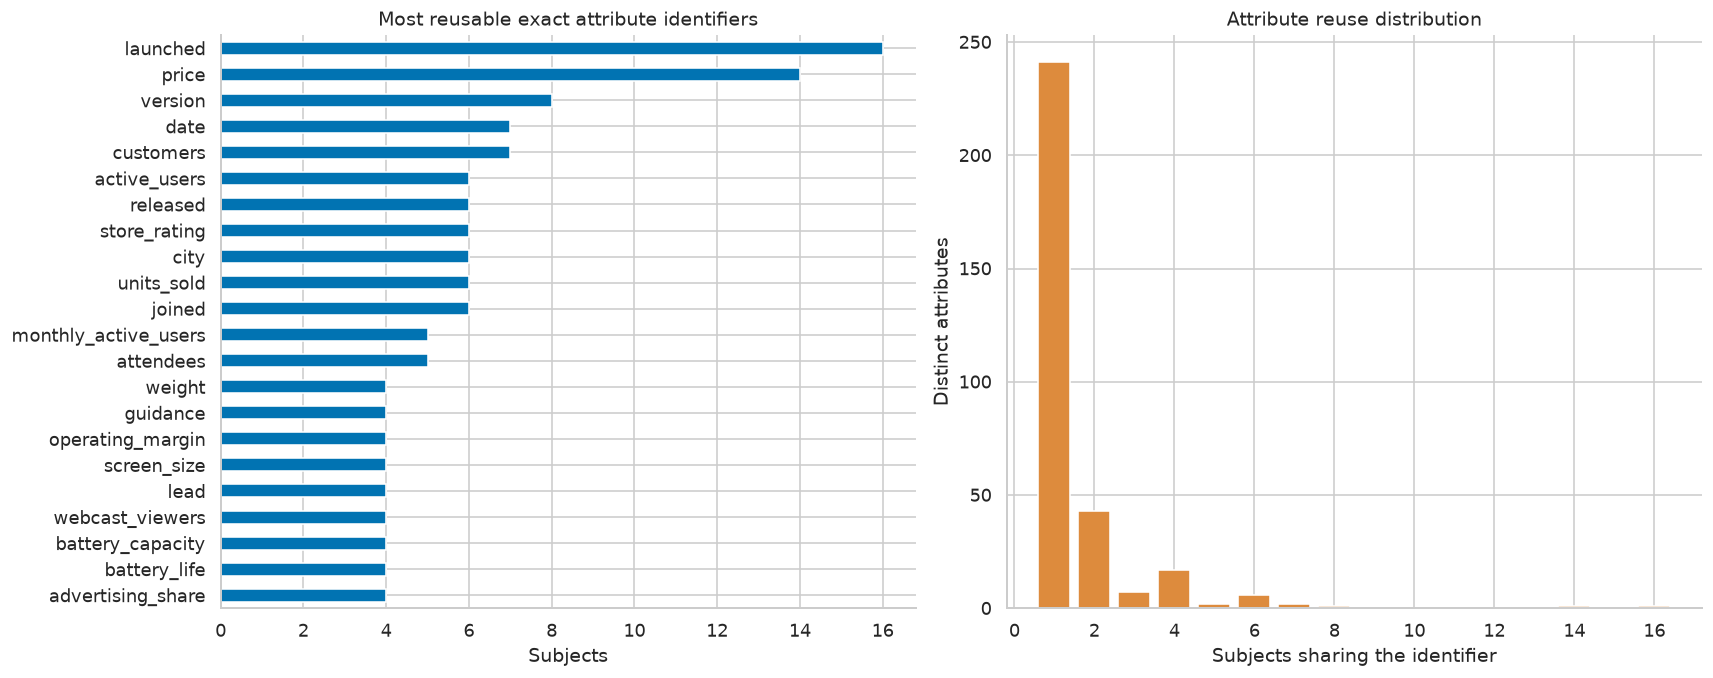

**Measured:** **75.1%** of distinct attributes appear on one subject; they account for **46.9%** of all slots. A model trained only on common attribute names will leave a substantial long tail uncovered.

In [10]:
attribute_inventory = pd.DataFrame({"attribute": attribute_counts.index, "subject_count": attribute_counts.values})
attribute_inventory["subjects"] = attribute_inventory.attribute.map(attribute_subjects)
attribute_inventory["tokens"] = attribute_inventory.attribute.map(lambda a: a.split("_"))
attribute_inventory["token_count"] = attribute_inventory.tokens.str.len()
attribute_inventory["is_singleton"] = attribute_inventory.subject_count.eq(1)
display(attribute_inventory.head(25))
reuse_distribution = attribute_inventory.subject_count.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
attribute_inventory.head(22).sort_values("subject_count").plot.barh(x="attribute", y="subject_count", legend=False, ax=axes[0])
axes[0].set(title="Most reusable exact attribute identifiers", xlabel="Subjects", ylabel="")
axes[1].bar(reuse_distribution.index, reuse_distribution.values, color="#dd8b3d")
axes[1].set(title="Attribute reuse distribution", xlabel="Subjects sharing the identifier", ylabel="Distinct attributes")
finish_figure("06_attribute_reuse")
singleton_slot_share = int(attribute_inventory.is_singleton.sum()) / len(slots)
display(Markdown(f"**Measured:** **{attribute_inventory.is_singleton.mean():.1%}** of distinct attributes appear on one subject; "
                 f"they account for **{singleton_slot_share:.1%}** of all slots. "
                 "A model trained only on common attribute names will leave a substantial long tail uncovered."))

In [11]:
token_rows = [{"attribute": a, "token": t} for a in attribute_inventory.attribute for t in set(a.split("_"))]
attribute_tokens = pd.DataFrame(token_rows)
token_stats = attribute_tokens.groupby("token").attribute.nunique().sort_values(ascending=False).rename("distinct_attributes").to_frame()
token_stats["slot_occurrences"] = attribute_tokens.merge(attribute_inventory[["attribute", "subject_count"]], on="attribute").groupby("token").subject_count.sum()
display(token_stats.head(25))
confusable_groups = {
    "Users / customers / devices": ["users", "active_users", "monthly_active_users", "customers", "paying_customers", "active_devices"],
    "Versions": ["version", "stable_version", "api_version", "cli_version", "version_history"],
    "Languages": ["languages", "languages_supported", "languages_served", "caption_languages", "voice_guidance_languages", "programming_languages", "offline_languages"],
    "Release milestones": ["released", "launched", "announced", "beta_opened", "stable_release", "planned_general_availability", "generally_available"],
    "Price scope": ["price", "annual_price", "price_per_user", "extra_seat_price", "standard_storage_price"],
    "Storage scope": ["storage", "base_storage", "free_storage", "storage_per_user", "mailbox_storage", "max_file_size", "max_upload_size"],
    "Reliability": ["uptime_sla", "uptime_last_quarter", "had_major_outage", "incidents_this_year"],
}
confusable_attributes = pd.DataFrame([{"review_group": group, "attribute": a,
                                      "subjects": attribute_subjects.get(a, [])}
                                     for group, attrs in confusable_groups.items() for a in attrs])
show_all(confusable_attributes)

,distinct_attributes,slot_occurrences
token,,
price,10,28
size,9,15
storage,9,16
per,8,10
max,8,9
languages,7,8
share,7,12
time,7,8
free,6,10


,review_group,attribute,subjects
0,Users / customers / devices,users,[Hooly Jules]
1,Users / customers / devices,active_users,"[Hooly Calendar, Hooly Docs, Hooly Drive, Hooly Gmail, Hooly Meet, Hooly Sheets]"
2,Users / customers / devices,monthly_active_users,"[Hooly Chrome, Hooly Maps, Hooly Photos, Hooly Search, Hooly Translate]"
3,Users / customers / devices,customers,"[Hooly Cloud, Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results, Hooly Workspace, Hooly Workspace Enterprise]"
4,Users / customers / devices,paying_customers,[Hooly]
5,Users / customers / devices,active_devices,[Hooly Android]
6,Versions,version,"[Hooly Android, Hooly Calendar, Hooly Docs, Hooly Gemini, Hooly Jules, Hooly Maps, Hooly Photos, Hooly Sheets]"
7,Versions,stable_version,[Hooly Chrome]
8,Versions,api_version,[Hooly Gemini]
9,Versions,cli_version,[Hooly Cloud]


<a id="structure"></a>
## 8. Subject–attribute structure

The incidence matrix is binary: a cell is 1 only when the JSON permits that attribute on that subject.
The graph is bipartite, with separate subject and attribute nodes. Degree and connected components describe
**schema connectivity**, not evidence strength. Subjects with identical schemas need entity-specific evidence.

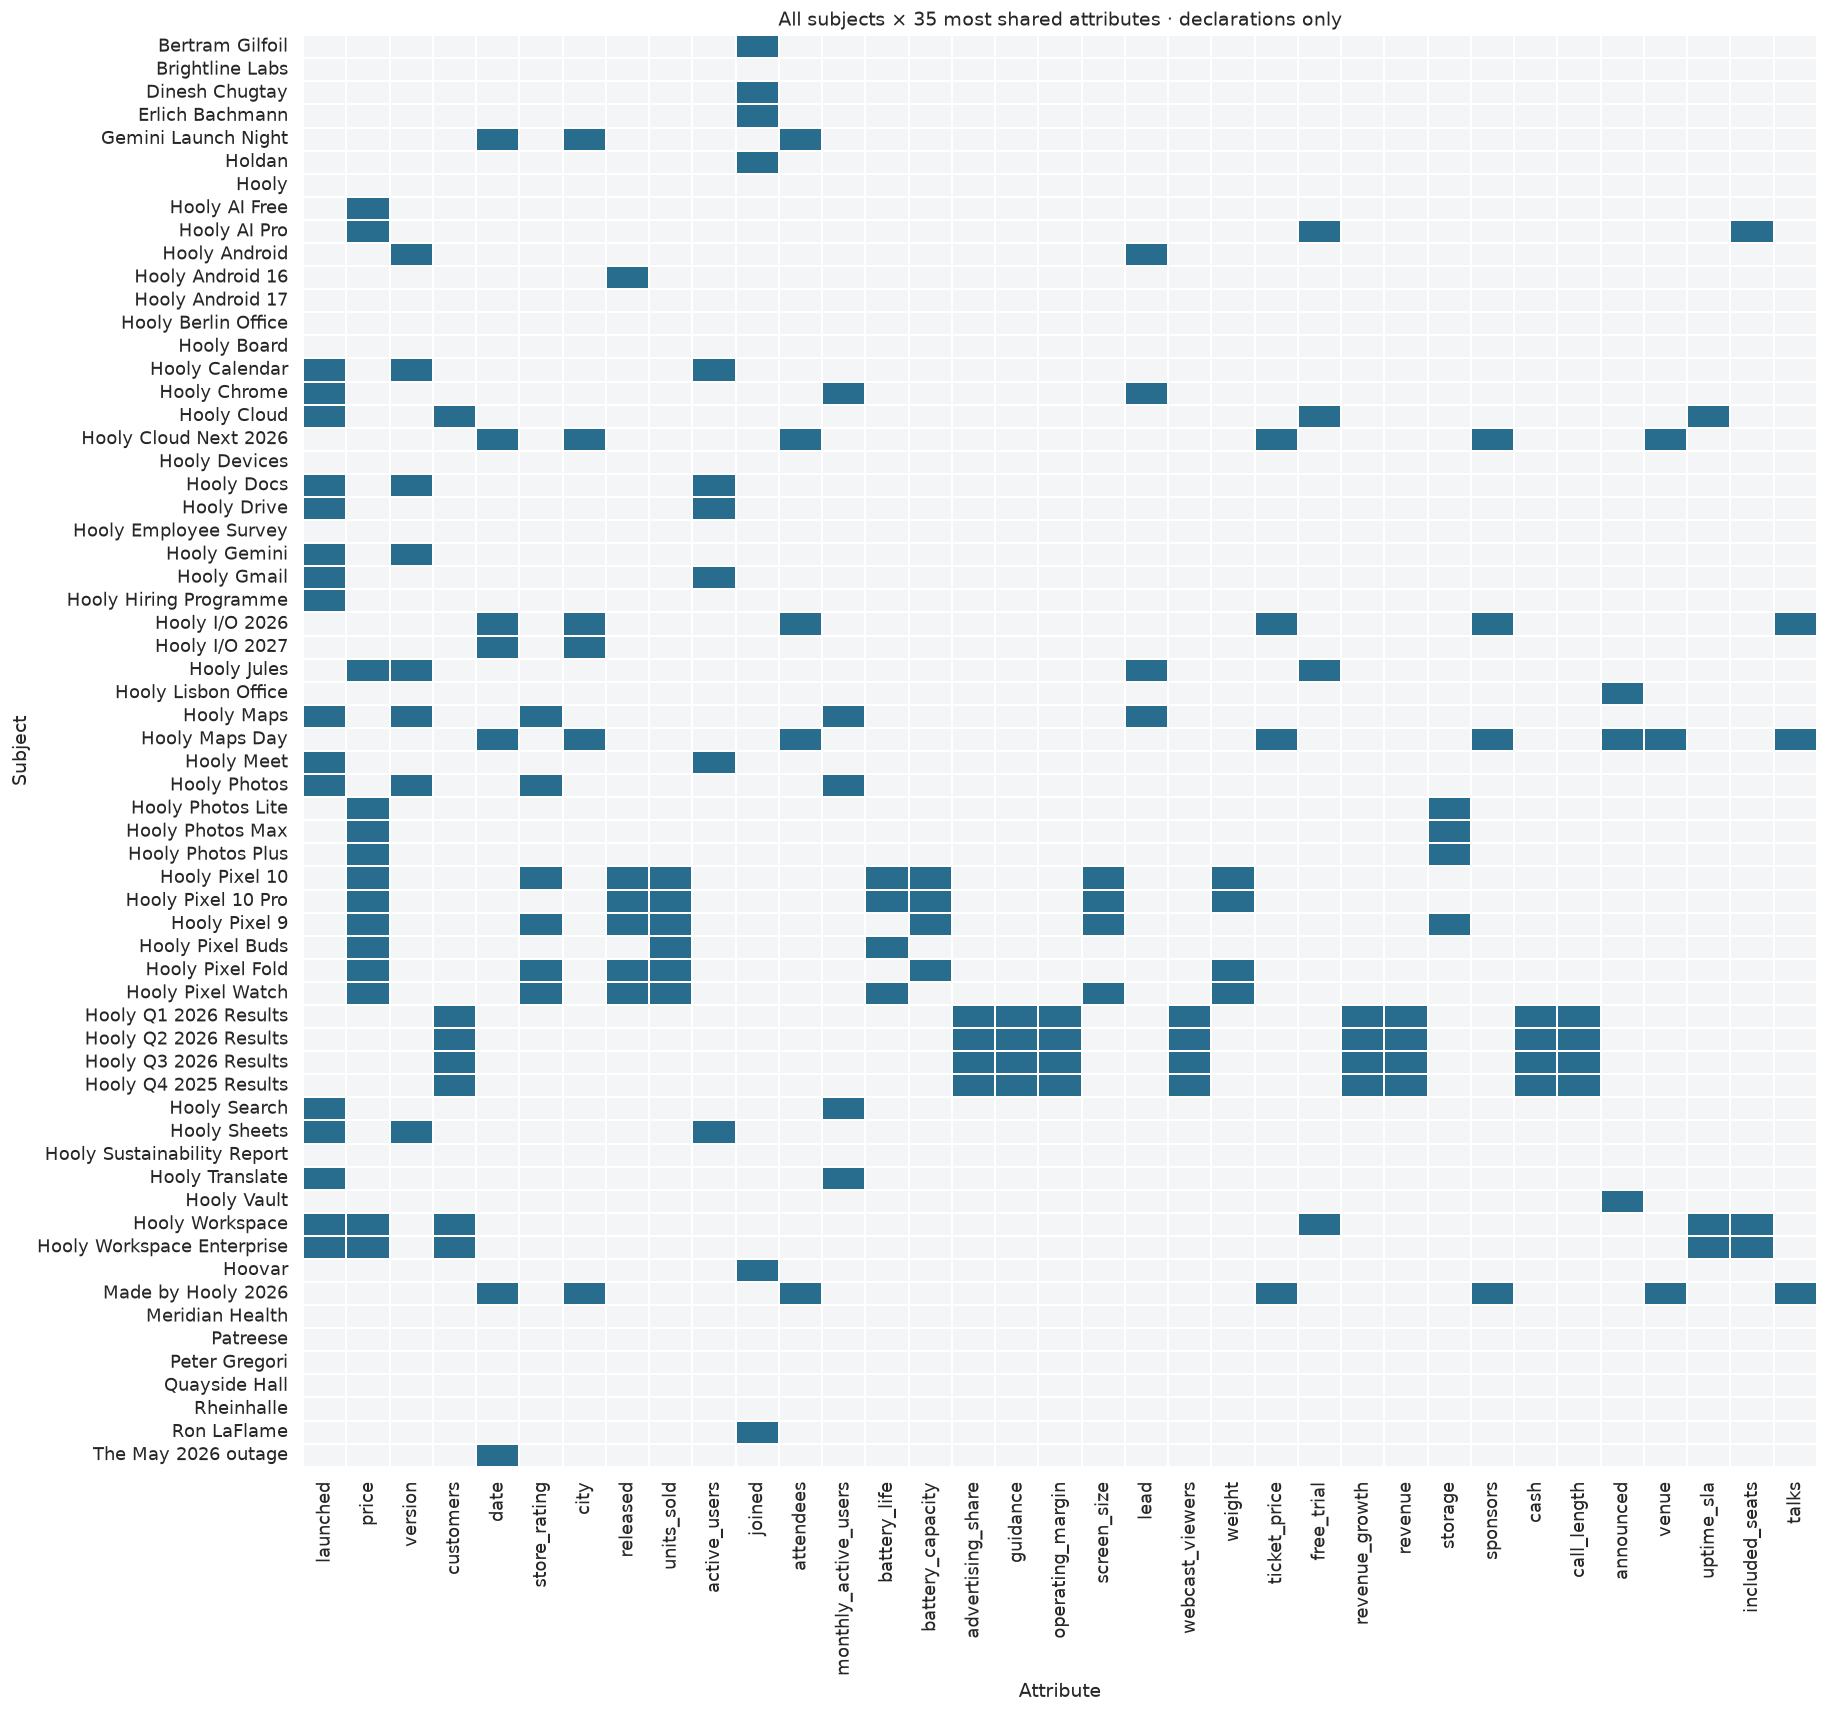

**Measured:** full matrix shape **62 × 321**, density **2.58%**. A zero means 'not declared', not 'false'.

In [12]:
incidence = pd.crosstab(slots.subject, slots.attribute).clip(upper=1)
incidence = incidence.reindex(index=sorted(names_raw), columns=sorted(attribute_counts.index))
density = incidence.to_numpy().mean()
common_attrs = attribute_counts.head(35).index
plt.figure(figsize=(16, 15))
sns.heatmap(incidence[common_attrs], cmap=["#f3f5f7", "#286c8e"], cbar=False, linewidths=0.15,
            xticklabels=True, yticklabels=True)
plt.title("All subjects × 35 most shared attributes · declarations only")
plt.xlabel("Attribute"); plt.ylabel("Subject")
finish_figure("07_incidence_heatmap")
display(Markdown(f"**Measured:** full matrix shape **{incidence.shape[0]} × {incidence.shape[1]}**, "
                 f"density **{density:.2%}**. A zero means 'not declared', not 'false'."))

In [13]:
B = nx.Graph()
for row in slots.itertuples():
    B.add_edge(("subject", row.subject), ("attribute", row.attribute))
component_rows = []
for component in sorted(nx.connected_components(B), key=len, reverse=True):
    ss = sorted(v for kind, v in component if kind == "subject")
    aa = sorted(v for kind, v in component if kind == "attribute")
    component_rows.append({"subject_count": len(ss), "attribute_count": len(aa), "subjects": ss, "attributes": aa})
components = pd.DataFrame(component_rows)
display(components)
schema_groups = defaultdict(list)
for subject, attrs in subject_attributes.items():
    schema_groups[tuple(sorted(attrs))].append(subject)
identical_schemas = pd.DataFrame([{"subjects": ss, "attributes": list(attrs), "subject_count": len(ss)}
                                 for attrs, ss in schema_groups.items() if len(ss) > 1])
show_all(identical_schemas)
display(Markdown("**Interpretation:** disconnected schemas can require specialised extractors. "
                 "Identical schemas are valuable discrimination tests: knowing that a sentence concerns 'price' and 'storage' "
                 "does not identify which Photos plan it names."))

,subject_count,attribute_count,subjects,attributes
0,48,289,"[Gemini Launch Night, Hooly, Hooly AI Free, Hooly AI Pro, Hooly Android, Hooly Android 16, Hooly...","[active_devices, active_users, ad_free_option, ad_free_price, adaptive_noise_cancelling, adverti..."
1,7,6,"[Bertram Gilfoil, Dinesh Chugtay, Erlich Bachmann, Holdan, Hoovar, Patreese, Ron LaFlame]","[desks_managed, facilities_team, joined, offices_run, previous_employer, team_size]"
2,1,10,[Hooly Board],"[attendance, audit_committee, chair, chair_since, independent_members, meetings_per_year, next_m..."
3,1,10,[Hooly Employee Survey],"[anonymous, growth_opportunities, manageable_workload, manager_rating, next_round, open_for, res..."
4,1,3,[Peter Gregori],"[chairs, chairs_audit_committee, independent_director]"
5,2,1,"[Quayside Hall, Rheinhalle]",[capacity]
6,1,1,[Brightline Labs],[integration_partner_of_flawless]
7,1,1,[Meridian Health],[flawless_seats]


,subjects,attributes,subject_count
0,"[Dinesh Chugtay, Erlich Bachmann, Ron LaFlame]",[joined],3
1,"[Hooly Photos Lite, Hooly Photos Max, Hooly Photos Plus]","[price, storage]",3
2,"[Hooly Q2 2026 Results, Hooly Q3 2026 Results]","[advertising_share, call_length, cash, customers, guidance, operating_margin, revenue, revenue_growth, webcast_viewers]",2
3,"[Quayside Hall, Rheinhalle]",[capacity],2


**Interpretation:** disconnected schemas can require specialised extractors. Identical schemas are valuable discrimination tests: knowing that a sentence concerns 'price' and 'storage' does not identify which Photos plan it names.

<a id="similarity"></a>
## 9. Similarity and candidate families

For attribute sets A and B, **Jaccard = |A∩B| / |A∪B|**. We also compute a weighted version with
`weight(attribute) = log((N + 1)/(subject_count + 1)) + 1`, reducing the influence of ubiquitous attributes.
Both are schema similarity, not semantic or truth similarity. Thresholded components are exploratory:
transitive connections need not mean every member is similar to every other member.

,left,right,shared_count,jaccard,weighted_jaccard,shared_attributes
1720,Hooly Q2 2026 Results,Hooly Q3 2026 Results,9,1.000000,1.000000,"[advertising_share, call_length, cash, customers, guidance, operating_margin, revenue, revenue_g..."
1485,Hooly Photos Lite,Hooly Photos Max,2,1.000000,1.000000,"[price, storage]"
1486,Hooly Photos Lite,Hooly Photos Plus,2,1.000000,1.000000,"[price, storage]"
1513,Hooly Photos Max,Hooly Photos Plus,2,1.000000,1.000000,"[price, storage]"
121,Dinesh Chugtay,Erlich Bachmann,1,1.000000,1.000000,[joined]
178,Dinesh Chugtay,Ron LaFlame,1,1.000000,1.000000,[joined]
236,Erlich Bachmann,Ron LaFlame,1,1.000000,1.000000,[joined]
1885,Quayside Hall,Rheinhalle,1,1.000000,1.000000,[capacity]
1703,Hooly Q1 2026 Results,Hooly Q4 2025 Results,10,0.909091,0.897405,"[advertising_share, call_length, cash, customers, guidance, headcount, operating_margin, revenue..."
1701,Hooly Q1 2026 Results,Hooly Q2 2026 Results,9,0.900000,0.885676,"[advertising_share, call_length, cash, customers, guidance, operating_margin, revenue, revenue_g..."


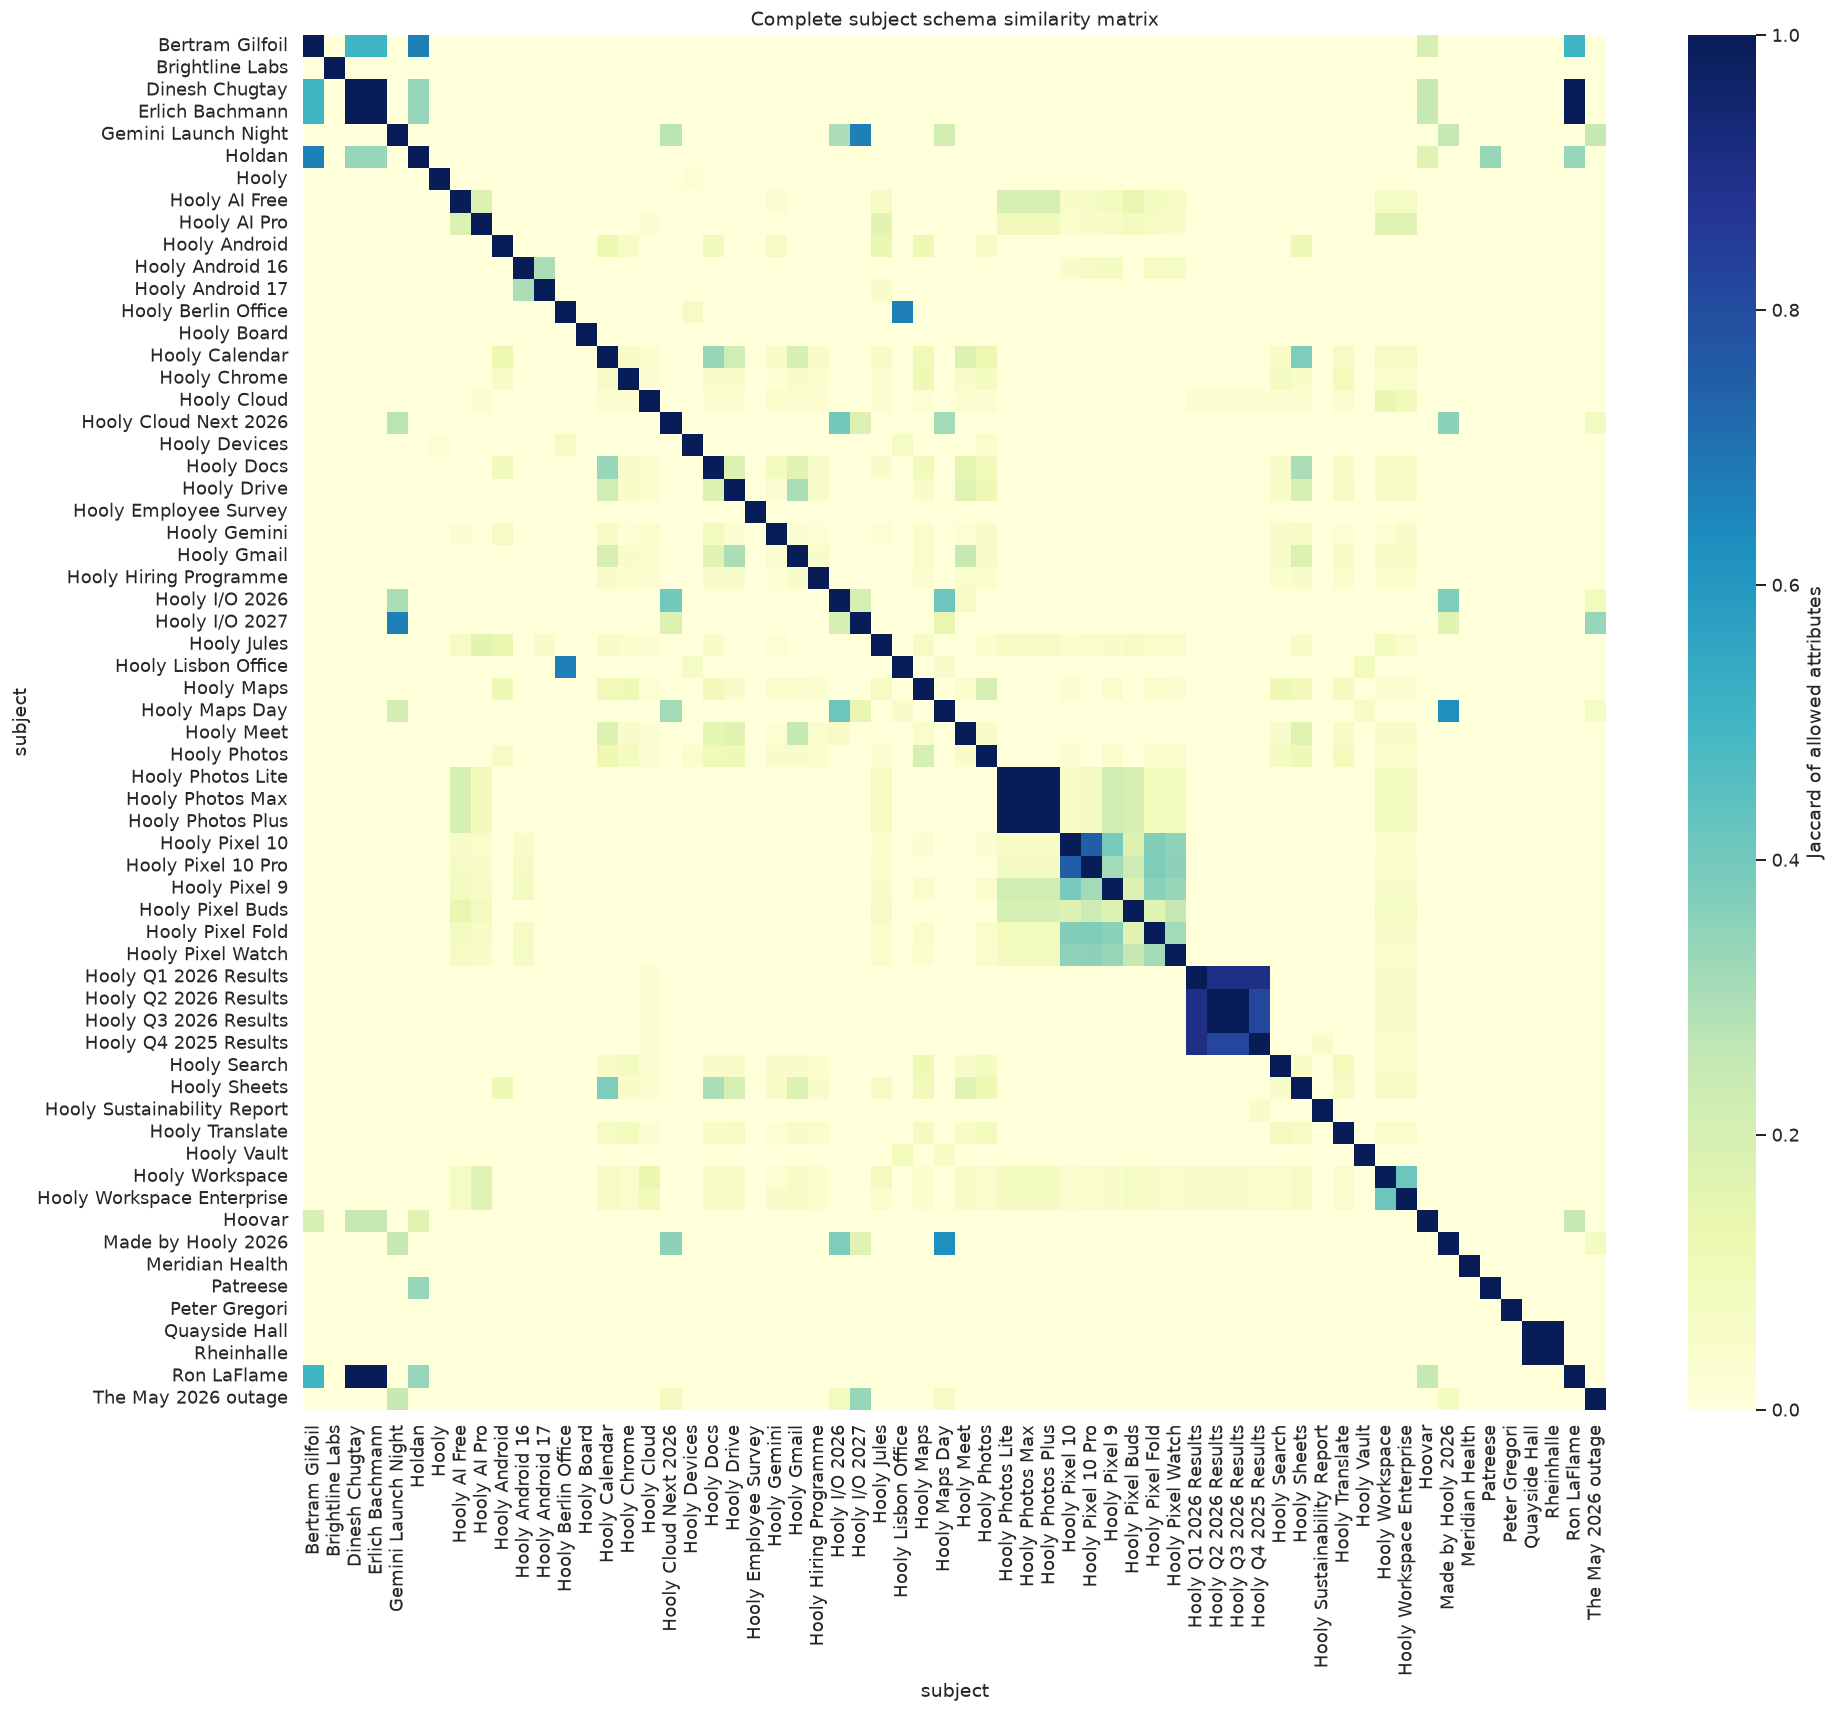

In [14]:
idf = {a: math.log((N + 1) / (count + 1)) + 1 for a, count in attribute_counts.items()}
similarity_rows = []
for left, right in combinations(sorted(names_raw), 2):
    a, b = subject_attributes[left], subject_attributes[right]
    intersection, union = a & b, a | b
    similarity_rows.append({"left": left, "right": right, "shared_count": len(intersection),
                            "jaccard": len(intersection) / len(union),
                            "weighted_jaccard": sum(idf[x] for x in intersection) / sum(idf[x] for x in union),
                            "shared_attributes": sorted(intersection)})
similarities = pd.DataFrame(similarity_rows).sort_values(["jaccard", "shared_count"], ascending=False)
display(similarities.head(25))
J = pd.DataFrame(np.eye(N), index=incidence.index, columns=incidence.index)
for row in similarities.itertuples():
    J.loc[row.left, row.right] = J.loc[row.right, row.left] = row.jaccard
plt.figure(figsize=(17, 15))
sns.heatmap(J, vmin=0, vmax=1, cmap="YlGnBu", xticklabels=True, yticklabels=True,
            cbar_kws={"label": "Jaccard of allowed attributes"})
plt.title("Complete subject schema similarity matrix")
finish_figure("08_schema_similarity")

,threshold,edges,components,isolated_subjects,largest_component
0,0.25,55,32,21,7
1,0.35,33,41,31,5
2,0.50,21,48,40,5
3,0.75,14,53,48,4
4,1.00,8,56,52,3


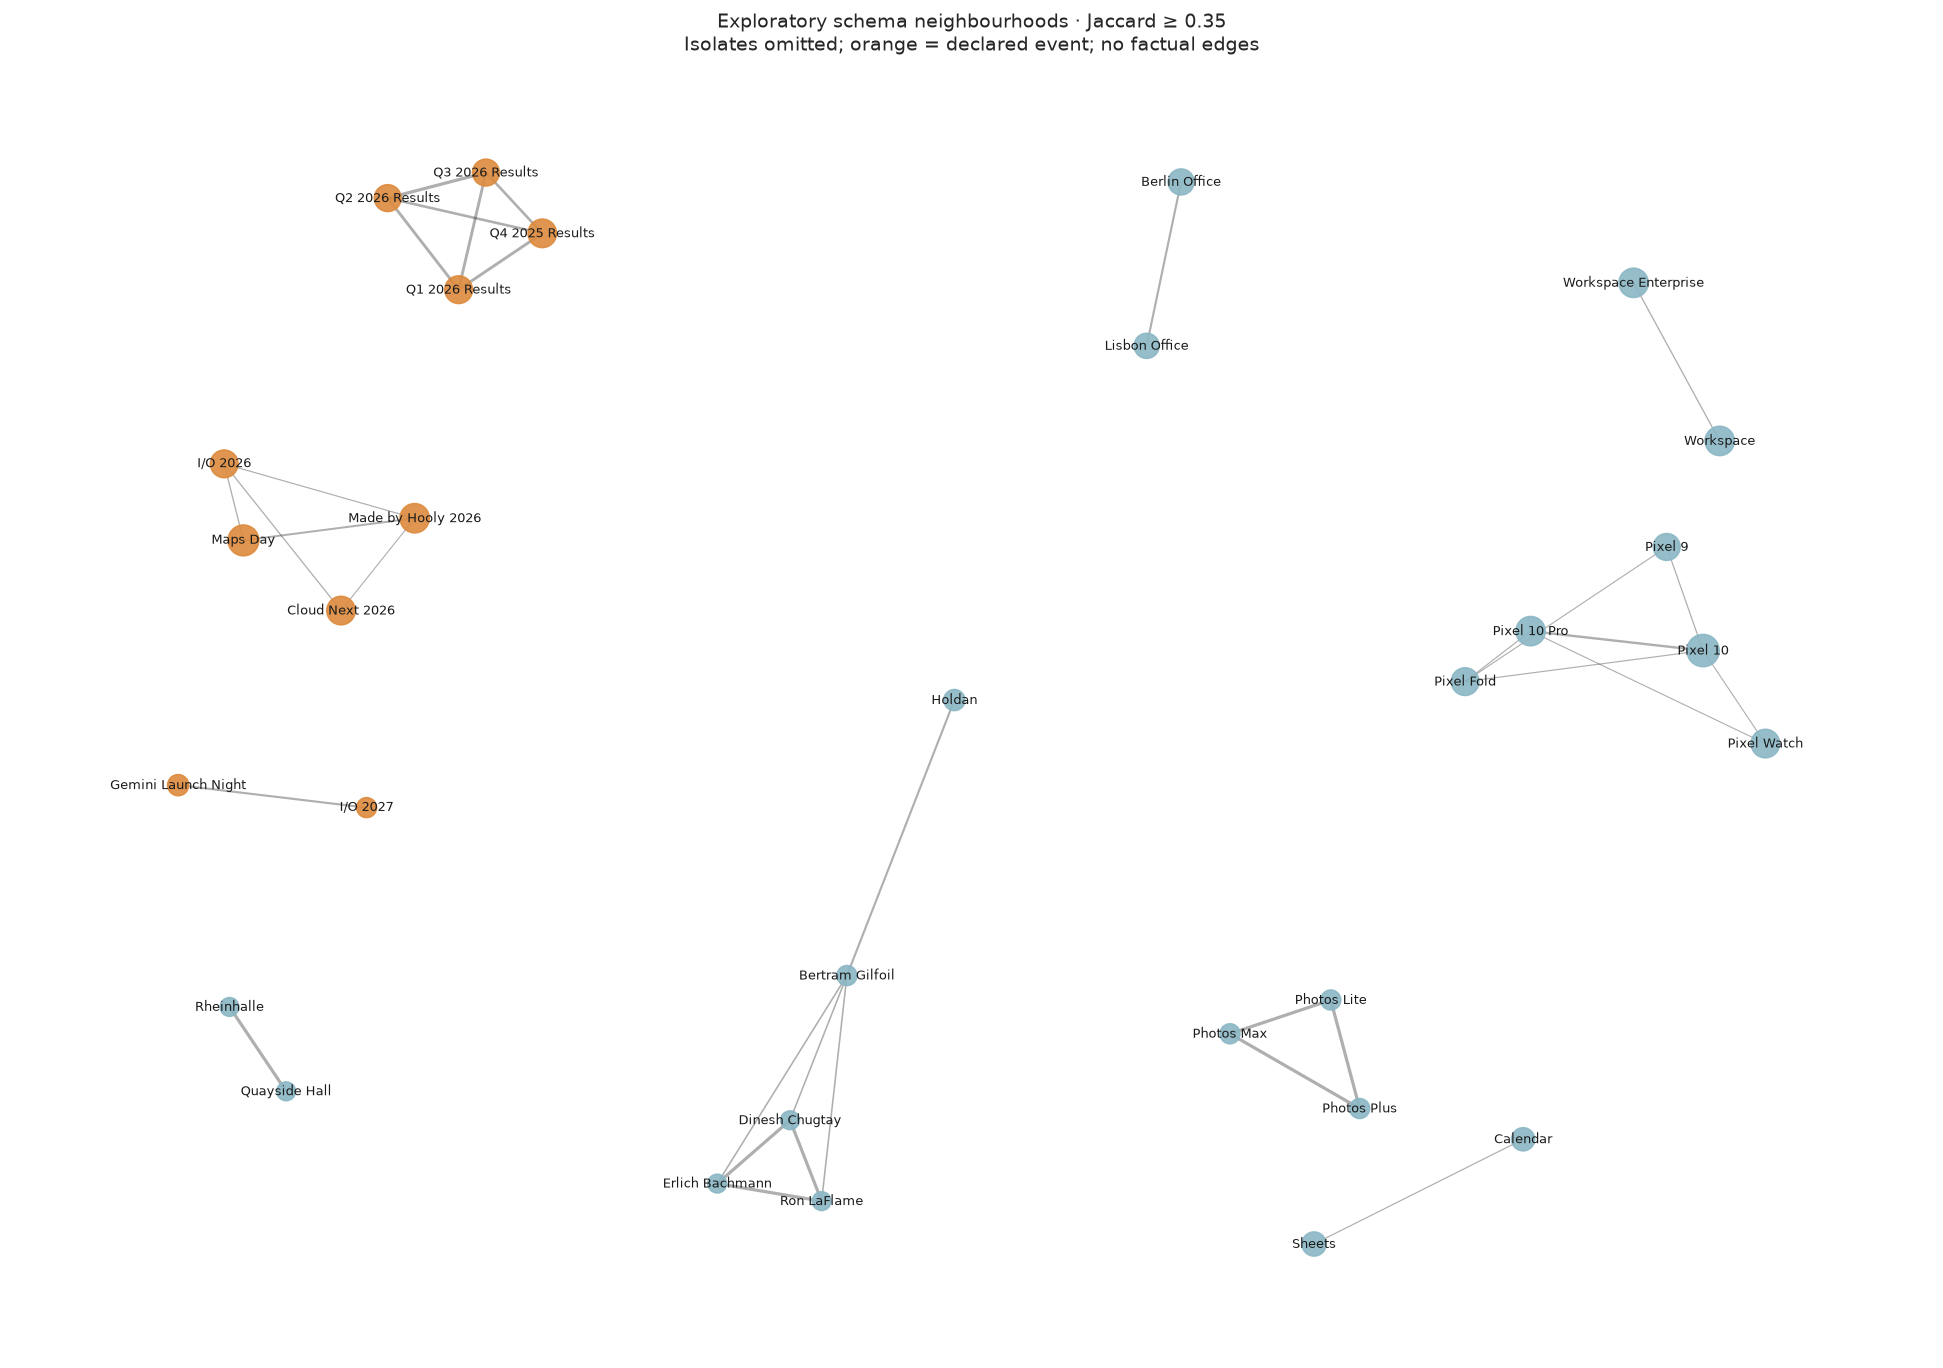

In [15]:
threshold_rows = []
for threshold in [0.25, 0.35, 0.50, 0.75, 1.0]:
    graph = nx.Graph()
    graph.add_nodes_from(names_raw)
    graph.add_edges_from(similarities.loc[similarities.jaccard >= threshold, ["left", "right"]].itertuples(index=False, name=None))
    groups = list(nx.connected_components(graph))
    threshold_rows.append({"threshold": threshold, "edges": graph.number_of_edges(),
                           "components": len(groups), "isolated_subjects": len(list(nx.isolates(graph))),
                           "largest_component": max(map(len, groups))})
threshold_sensitivity = pd.DataFrame(threshold_rows)
display(threshold_sensitivity)
G = nx.Graph()
G.add_nodes_from(names_raw)
for row in similarities.loc[similarities.jaccard >= 0.35].itertuples():
    G.add_edge(row.left, row.right, weight=row.jaccard)
connected = G.subgraph([n for n in G if G.degree(n) > 0]).copy()
plt.figure(figsize=(17, 12))
pos = nx.spring_layout(connected, seed=SEED, k=1.1, iterations=150)
nx.draw_networkx_nodes(connected, pos, node_size=[120 + 18 * len(subject_attributes[n]) for n in connected],
                       node_color=["#dd8b3d" if n in event_names else "#8bb7c5" for n in connected], alpha=0.9)
nx.draw_networkx_edges(connected, pos, width=[2 * connected[u][v]["weight"] for u, v in connected.edges], alpha=0.35)
nx.draw_networkx_labels(connected, pos, labels={n: n.removeprefix("Hooly ") for n in connected}, font_size=8)
plt.title("Exploratory schema neighbourhoods · Jaccard ≥ 0.35\nIsolates omitted; orange = declared event; no factual edges")
plt.axis("off")
finish_figure("09_schema_neighbourhood_graph")

### A reviewable family annotation, not a new ground truth

The following broad families are analyst-created navigation and test-stratification aids. Every subject
is shown in the final atlas so assignments can be reviewed. Explicit event membership takes precedence;
`other / review` keeps unresolved cases visible. These annotations must never establish ownership, entity type,
attribute inheritance, or truth labels.

In [16]:
people_review = {"Bertram Gilfoil", "Dinesh Chugtay", "Erlich Bachmann", "Holdan", "Hoovar", "Patreese", "Peter Gregori", "Ron LaFlame"}
organisations_review = {"Brightline Labs", "Meridian Health"}
venues_review = {"Quayside Hall", "Rheinhalle"}
def family_hypothesis(name):
    if name in event_names: return "declared event"
    if name in people_review: return "person (hypothesis)"
    if name in organisations_review: return "external organisation (hypothesis)"
    if name in venues_review: return "venue (hypothesis)"
    if "Office" in name: return "office (hypothesis)"
    if name.startswith("Hooly Pixel"): return "device (hypothesis)"
    if name in {"Hooly", "Hooly Board", "Hooly Devices", "Hooly Hiring Programme"}: return "organisation / programme (hypothesis)"
    if name.startswith(("Hooly AI ", "Hooly Photos ", "Hooly Workspace")): return "plan / suite (hypothesis)"
    if name.startswith("Hooly "): return "software / service (hypothesis)"
    return "other / review"
subjects["family_hypothesis"] = subjects.subject.map(family_hypothesis)
family_summary = subjects.groupby("family_hypothesis").agg(subjects=("subject", "size"),
    slots=("attribute_count", "sum"), aliases=("alias_count", "sum"),
    median_breadth=("attribute_count", "median"))
display(family_summary)
family_reuse = slots.merge(subjects[["subject", "family_hypothesis"]], on="subject").groupby("attribute").family_hypothesis.nunique()
display(family_reuse.sort_values(ascending=False).head(15).rename("hypothesised_families"))

,subjects,slots,aliases,median_breadth
family_hypothesis,,,,
declared event,13,113,15,10.0
device (hypothesis),6,62,6,10.5
external organisation (hypothesis),2,2,2,1.0
office (hypothesis),2,15,2,7.5
organisation / programme (hypothesis),4,66,6,12.5
person (hypothesis),8,16,0,1.5
plan / suite (hypothesis),7,43,5,4.0
software / service (hypothesis),18,195,12,8.0
venue (hypothesis),2,2,0,1.0


attribute
customers             3
price                 3
launched              3
announced             3
storage               2
single_sign_on        2
uptime_sla            2
head                  2
livestream_viewers    2
max_upload_size       2
annual_price          2
released              2
staff                 2
free_trial            2
store_rating          2
Name: hypothesised_families, dtype: int64

<a id="cooccurrence"></a>
## 10. Attribute co-occurrence

For each pair, support counts subjects declaring both attributes. **Lift = P(A∩B)/(P(A)P(B))**, using subjects
as the denominator. High lift can be caused by very small supports, so the displayed ranking requires support ≥ 3.
No causal or truth interpretation follows. Identical attribute columns suggest shared schema templates, not synonyms.

,left,right,support,lift,subjects
55,advertising_share,call_length,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
56,advertising_share,cash,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
58,advertising_share,guidance,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
60,advertising_share,operating_margin,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
62,advertising_share,revenue,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
63,advertising_share,revenue_growth,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
64,advertising_share,webcast_viewers,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
475,call_length,cash,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
477,call_length,guidance,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"
479,call_length,operating_margin,4,15.5,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]"


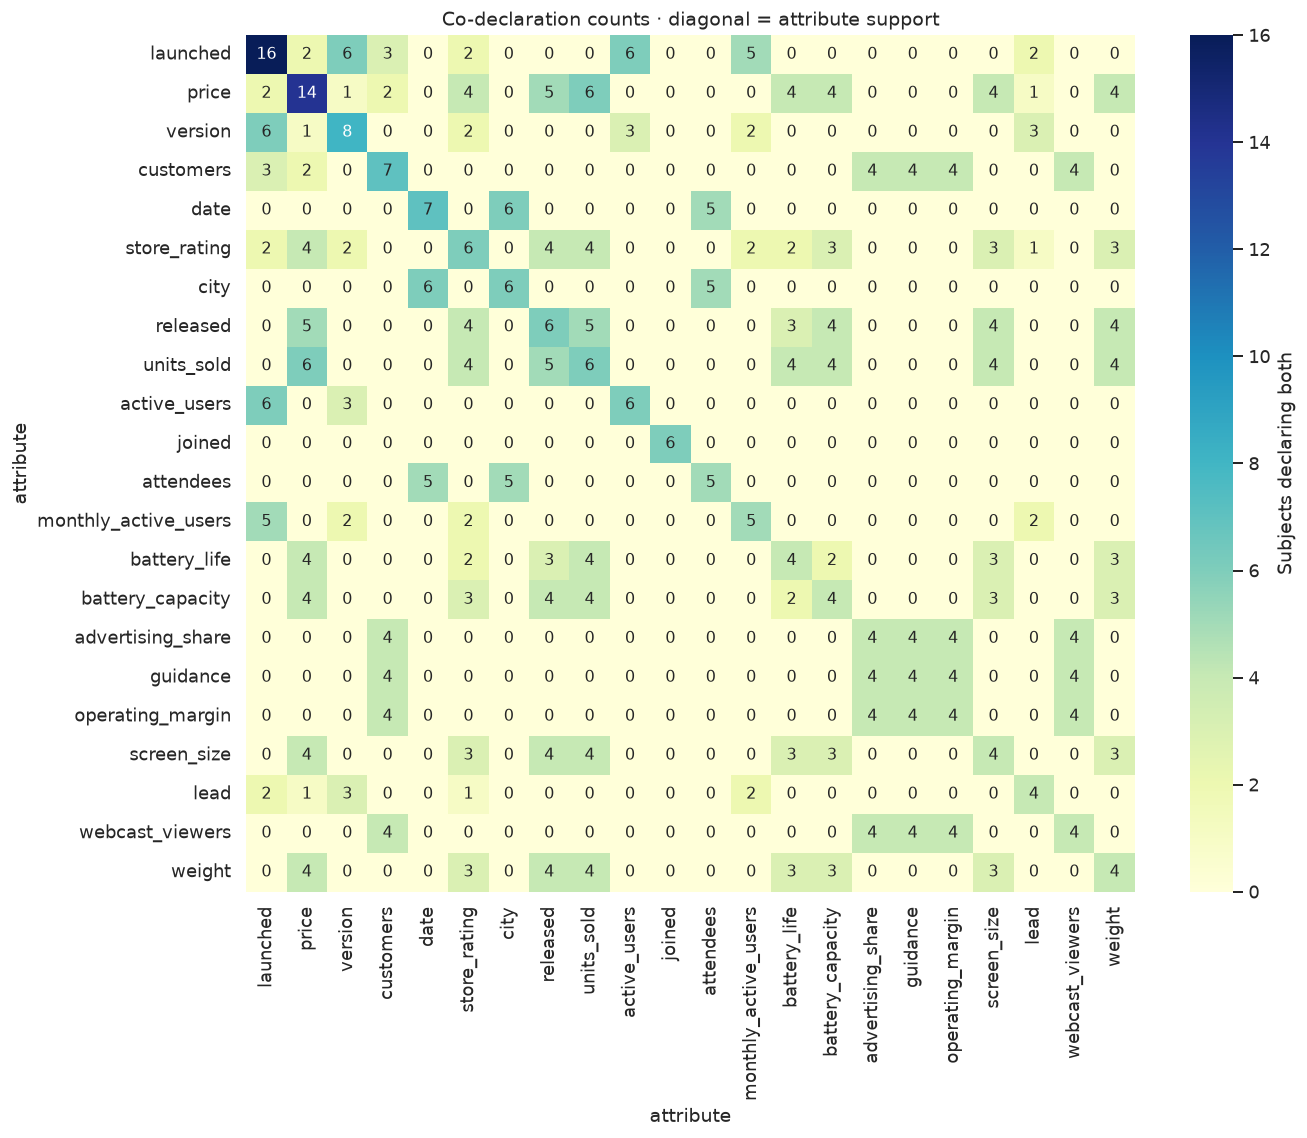

,attributes,subjects,support
0,"[advertising_share, call_length, cash, guidance, operating_margin, revenue, revenue_growth, webc...","[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]",4
6,"[sponsors, ticket_price]","[Hooly Cloud Next 2026, Hooly I/O 2026, Hooly Maps Day, Made by Hooly 2026]",4
1,"[apps_included, storage_per_user]","[Hooly Workspace, Hooly Workspace Enterprise]",2
2,"[bike_racks, desks, lease_end, opened, rent]","[Hooly Berlin Office, Hooly Lisbon Office]",2
3,"[charging_power, colours, main_camera, memory]","[Hooly Pixel 10, Hooly Pixel 10 Pro]",2
4,"[host, replay_available, stream_viewers]","[Hooly Maps Day, Made by Hooly 2026]",2
5,"[share_of_devices, supported_models, update_size]","[Hooly Android 16, Hooly Android 17]",2


In [17]:
co_rows = []
for left, right in combinations(sorted(attribute_counts.index), 2):
    both = set(attribute_subjects[left]) & set(attribute_subjects[right])
    if both:
        co_rows.append({"left": left, "right": right, "support": len(both),
                        "lift": N * len(both) / (len(attribute_subjects[left]) * len(attribute_subjects[right])),
                        "subjects": sorted(both)})
cooccurrence = pd.DataFrame(co_rows)
display(cooccurrence.query("support >= 3").sort_values(["lift", "support"], ascending=False).head(25))
top = attribute_counts.head(22).index
co_matrix = incidence[top].T.dot(incidence[top])
plt.figure(figsize=(12, 10))
sns.heatmap(co_matrix, cmap="YlGnBu", annot=True, fmt="d", cbar_kws={"label": "Subjects declaring both"})
plt.title("Co-declaration counts · diagonal = attribute support")
finish_figure("10_attribute_cooccurrence")
signature_groups = defaultdict(list)
for attr, owners in attribute_subjects.items(): signature_groups[tuple(owners)].append(attr)
same_support = pd.DataFrame([{"attributes": attrs, "subjects": list(owners), "support": len(owners)}
                             for owners, attrs in signature_groups.items() if len(attrs) > 1 and len(owners) > 1])
display(same_support.sort_values("support", ascending=False))

<a id="events"></a>
## 11. Events and temporal blind spots

An event name authorises an `at_event` reference, but this file supplies **no actual dates**.
A year or quarter inside a name is a name component, not evidence of the event's day.
`published`, `next_round`, and `date` are different attributes; we do not silently substitute one for another.

,subject,aliases,attributes,attribute_count,has_date_attribute,other_temporal_candidates,digits_in_name
4,Gemini Launch Night,[Launch Night],"[attendees, city, date]",3,True,[],[]
17,Hooly Cloud Next 2026,"[Hooly Cloud Next, Cloud Next]","[attendees, city, date, length, opening_keynote, registrations, sessions, speakers, sponsors, ticket_price, venue]",11,True,[],[2026]
21,Hooly Employee Survey,[Employee Survey],"[anonymous, growth_opportunities, manageable_workload, manager_rating, next_round, open_for, respondents, response_rate, run_by, would_recommend]",10,False,[next_round],[]
25,Hooly I/O 2026,[Hooly I/O],"[attendees, city, date, keynote_length, length, livestream_viewers, sponsors, talks, ticket_price, workshops]",10,True,[],[2026]
26,Hooly I/O 2027,"[next I/O, I/O 2027]","[city, date]",2,True,[],[2027]
30,Hooly Maps Day,[Maps Day],"[announced, attendees, city, date, features_launched, host, keynote_length, keynote_speaker, replay_available, sponsors, stream_viewers, talks, ticket_price, venue]",14,True,"[announced, features_launched]",[]
42,Hooly Q1 2026 Results,[Hooly's Q1 results],"[advertising_share, call_length, cash, customers, guidance, headcount, operating_margin, revenue, revenue_growth, webcast_viewers]",10,False,[],"[1, 2026]"
43,Hooly Q2 2026 Results,[Hooly's Q2 results],"[advertising_share, call_length, cash, customers, guidance, operating_margin, revenue, revenue_growth, webcast_viewers]",9,False,[],"[2, 2026]"
44,Hooly Q3 2026 Results,[Hooly's Q3 results],"[advertising_share, call_length, cash, customers, guidance, operating_margin, revenue, revenue_growth, webcast_viewers]",9,False,[],"[3, 2026]"
45,Hooly Q4 2025 Results,[Hooly's Q4 results],"[advertising_share, call_length, cash, customers, guidance, headcount, operating_margin, published, revenue, revenue_growth, webcast_viewers]",11,False,[published],"[4, 2025]"


,subject
attribute,
announced,"[Hooly Lisbon Office, Hooly Maps Day, Hooly Vault]"
beta_date,[Hooly Jules]
beta_opened,[Hooly Android 17]
chair_since,[Hooly Board]
date,"[Gemini Launch Night, Hooly Cloud Next 2026, Hooly I/O 2026, Hooly I/O 2027, Hooly Maps Day, Mad..."
features_launched,[Hooly Maps Day]
founded,"[Hooly, Hooly Devices]"
general_availability_date,[Hooly Jules]
joined,"[Bertram Gilfoil, Dinesh Chugtay, Erlich Bachmann, Holdan, Hoovar, Ron LaFlame]"


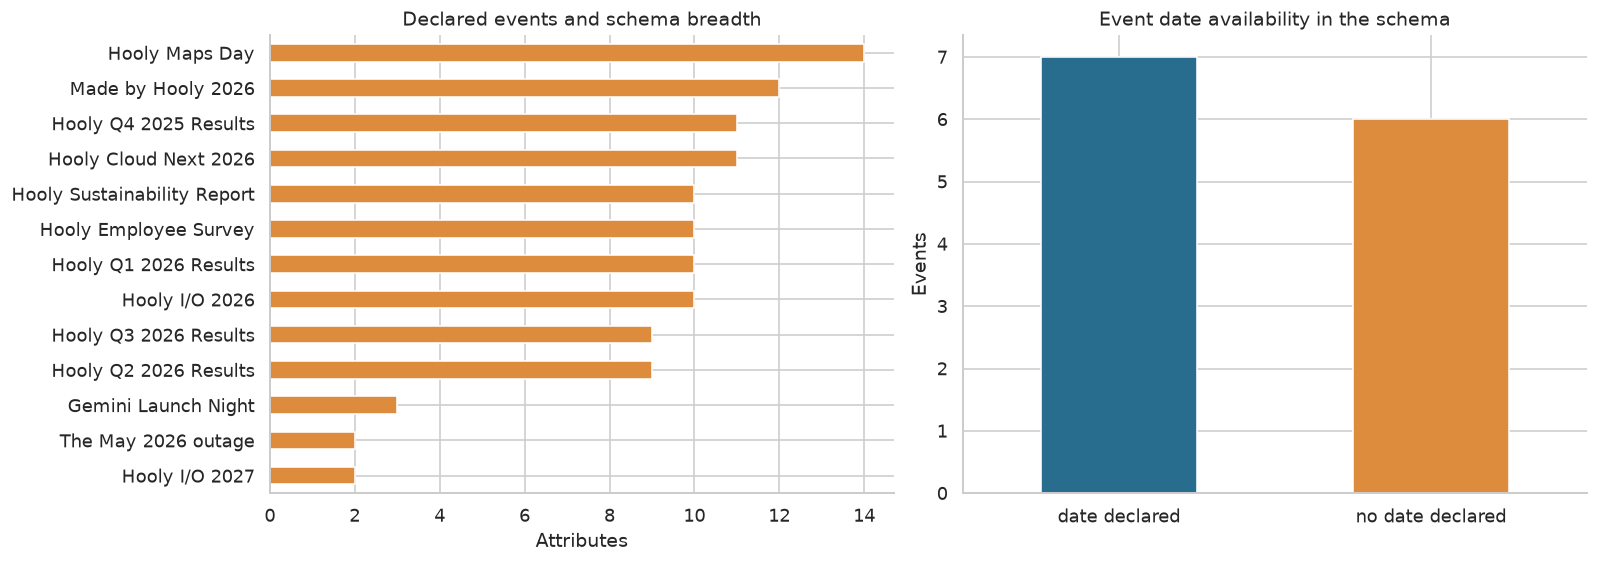

**Measured:** **6 of 13** events lack an explicit `date` attribute. Even those with `date` still have no value in this file. Resolving event dates is a priority for the later sentence study.

In [18]:
temporal_identifier = re.compile(r"date|launched|released|opened|announced|published|joined|founded|since|lease_end|next_meeting|next_round|beta_opened|stable_release|planned_general_availability")
event_audit = subjects.loc[subjects.is_event, ["subject", "aliases", "attributes", "attribute_count"]].copy()
event_audit["has_date_attribute"] = event_audit.attributes.map(lambda a: "date" in a)
event_audit["other_temporal_candidates"] = event_audit.attributes.map(lambda aa: [a for a in aa if a != "date" and temporal_identifier.search(a)])
event_audit["digits_in_name"] = event_audit.subject.str.findall(r"\d+")
show_all(event_audit)
temporal_slots = slots.loc[slots.attribute.map(lambda a: bool(temporal_identifier.search(a)))].copy()
display(temporal_slots.groupby("attribute").subject.agg(list).to_frame())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
event_audit.set_index("subject").attribute_count.sort_values().plot.barh(ax=axes[0], color="#dd8b3d")
axes[0].set(title="Declared events and schema breadth", xlabel="Attributes", ylabel="")
event_audit.has_date_attribute.value_counts().reindex([True, False], fill_value=0).set_axis(["date declared", "no date declared"]).plot.bar(ax=axes[1], rot=0, color=["#286c8e", "#dd8b3d"])
axes[1].set(title="Event date availability in the schema", ylabel="Events")
finish_figure("11_event_audit")
display(Markdown(f"**Measured:** **{int((~event_audit.has_date_attribute).sum())} of {len(event_audit)}** events "
                 "lack an explicit `date` attribute. Even those with `date` still have no value in this file. "
                 "Resolving event dates is a priority for the later sentence study."))

<a id="types"></a>
## 12. Value-type hypotheses and relation candidates

The contract allows eight value kinds, but the lexicon attaches **none** to its attributes.
Below is a deliberately incomplete, multi-label rule inventory. Each suggestion records its reason and status.
Overlapping hints remain overlapping; unrecognised attributes remain unresolved. These are triage aids, not trained predictions
or probability estimates. For example, `version_history` could be a duration or feature description; a substring rule must not
declare it a software version. `generally_available` suggests a boolean while `planned_general_availability` may be a date.

,attributes,slots
status,,
multiple hypotheses,6,7
single hypothesis; unverified,246,423
unresolved,69,84


,attribute,candidate_kinds,candidate_count,reasons,status,subject_count
18,archive_storage_price,"[money, quantity]",2,"{'money': ['financial wording; currency and period still unknown'], 'quantity': ['count/measurem...",multiple hypotheses,1
57,cool_storage_price,"[money, quantity]",2,"{'money': ['financial wording; currency and period still unknown'], 'quantity': ['count/measurem...",multiple hypotheses,1
77,devices_keynote_speaker,"[name, quantity]",2,"{'name': ['reviewed role/place/organisation identifier'], 'quantity': ['count/measurement wordin...",multiple hypotheses,1
175,memory_saver,"[boolean, quantity]",2,"{'boolean': ['reviewed capability/status identifier'], 'quantity': ['count/measurement wording; ...",multiple hypotheses,1
259,share_of_devices,"[percent, quantity]",2,"{'percent': ['ratio-like wording; may instead be a rate or score'], 'quantity': ['count/measurem...",multiple hypotheses,2
274,standard_storage_price,"[money, quantity]",2,"{'money': ['financial wording; currency and period still unknown'], 'quantity': ['count/measurem...",multiple hypotheses,1


,attribute,subject_count
16,apps_included,2
19,attachment_limit,1
20,attendance,1
24,availability_zones,1
33,business_listings,1
44,chairs,1
47,charging_stations_listed,1
53,colours,2
56,context_window,1
60,countries_covered,1


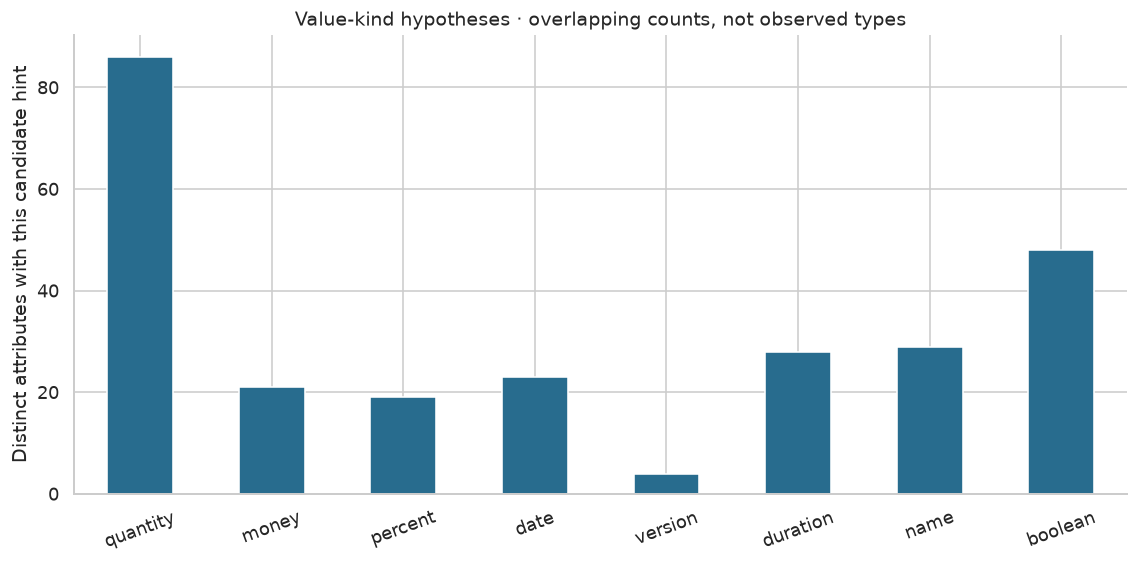

In [19]:
entry_schema = json.loads((ROOT / "contracts/entry.schema.json").read_text())
value_schema = json.loads((ROOT / "contracts/claimed_value.schema.json").read_text())
allowed_kinds = value_schema["properties"]["kind"]["enum"]
link_candidates = {"ceo", "cto", "head", "head_of_product", "head_of_security", "head_of_workspace",
    "founders", "lead", "reliability_lead", "previous_employer", "cloud_provider", "manufacturing_partner",
    "executive_owner", "executive_sponsor", "chair", "series_a_lead", "series_a_co_investor", "soc2_auditor",
    "host", "keynote_speaker", "devices_keynote_speaker", "owner", "run_by", "venue", "city", "headquarters",
    "primary_region", "home_region", "newest_region"}
boolean_candidates = {"open_source", "soc2_certified", "fully_remote", "had_major_outage", "single_sign_on",
    "ai_sidebar", "passkey_sync", "memory_saver", "desktop_mode", "on_device_gemini", "satellite_messaging",
    "carbon_neutral", "offline_editing", "anonymous", "encryption_at_rest", "eu_hosted", "image_input", "voice_mode",
    "end_to_end_encryption", "end_to_end_encrypted_backups", "ai_editing", "ar_walking", "offline_maps",
    "cloud_recording", "replay_available", "livestreamed", "is_engineering_hub", "is_headquarters", "externally_audited",
    "adaptive_noise_cancelling", "cellular_option", "ad_free_option", "ai_answers", "personalised_ads_by_default",
    "gemini_formula_assist", "camera_translation", "pro_tier", "generally_available", "copilot_included",
    "raised_series_a", "raised_series_b", "trade_in_programme", "appointment_booking", "audit_committee",
    "data_processing_agreement", "independent_director", "chairs_audit_committee", "raviqa_seat"}
duration_candidates = {"free_trial", "history_retention", "refund_window", "support_first_response", "cold_start_time",
    "release_cadence", "tab_sleep_delay", "median_time_to_recover", "data_retention", "median_response_time",
    "p99_response_time", "keynote_length", "length", "open_for", "first_reply", "time_to_hire", "max_call_length",
    "trash_retention", "battery_life", "update_promise", "full_charge_time", "call_length", "news_refresh_interval",
    "voice_latency", "audit_retention", "onboarding_time", "duration", "version_history"}
date_candidates = {"date", "joined", "founded", "launched", "released", "announced", "opened", "published",
    "discontinued", "chair_since", "lease_end", "next_meeting", "next_round", "beta_opened", "stable_release",
    "planned_general_availability", "soc2_audit_start", "training_data_cutoff"}
quantity_pattern = re.compile(r"(^|_)(users|customers|devices|languages|seats|regions|staff|employees|headcount|attendees|speakers|sponsors|sessions|talks|viewers|desks|testers|templates|requests|storage|memory|weight|capacity|size|power|distance|participants|guests|files|cells|roles|hires|offers|recruiters|applicants|respondents|sensors|centres|racks|units_sold)($|_)")
def type_hints(attribute):
    hints = defaultdict(list)
    def add(kind, reason): hints[kind].append(reason)
    if attribute in link_candidates: add("name", "reviewed role/place/organisation identifier")
    if attribute in boolean_candidates: add("boolean", "reviewed capability/status identifier")
    if attribute in duration_candidates: add("duration", "reviewed elapsed-time/retention identifier")
    if attribute in date_candidates or attribute.endswith("_date"): add("date", "milestone/date identifier")
    if attribute in {"version", "api_version", "cli_version", "stable_version"}: add("version", "exact version identifier")
    if re.search(r"price|rent|cash|cost|bonus|bounty|credit|series_a_amount|annual_recurring_revenue", attribute) or attribute == "revenue":
        add("money", "financial wording; currency and period still unknown")
    if re.search(r"share|rate|margin|uptime|accuracy|acceptance|discount|renewable_electricity", attribute):
        add("percent", "ratio-like wording; may instead be a rate or score")
    if quantity_pattern.search(attribute): add("quantity", "count/measurement wording; unit still unknown")
    return hints

type_rows = []
for attribute in sorted(attribute_counts.index):
    hints = type_hints(attribute)
    type_rows.append({"attribute": attribute, "candidate_kinds": sorted(hints),
                      "candidate_count": len(hints), "reasons": dict(hints),
                      "status": "unresolved" if not hints else ("multiple hypotheses" if len(hints) > 1 else "single hypothesis; unverified"),
                      "subject_count": int(attribute_counts[attribute])})
type_hypotheses = pd.DataFrame(type_rows)
display(type_hypotheses.groupby("status").agg(attributes=("attribute", "size"), slots=("subject_count", "sum")))
display(type_hypotheses.query("candidate_count > 1"))
display(type_hypotheses.query("candidate_count == 0")[["attribute", "subject_count"]])
assert set(k for kinds in type_hypotheses.candidate_kinds for k in kinds) <= set(allowed_kinds)
kind_counts = Counter(k for kinds in type_hypotheses.candidate_kinds for k in kinds)
plt.figure(figsize=(10, 5))
pd.Series(kind_counts).reindex(allowed_kinds, fill_value=0).plot.bar(color="#286c8e", rot=20)
plt.ylabel("Distinct attributes with this candidate hint")
plt.title("Value-kind hypotheses · overlapping counts, not observed types")
finish_figure("12_value_kind_hypotheses")

In [20]:
relation_candidates = slots.loc[slots.attribute.isin(link_candidates)].copy()
relation_candidates["target"] = "UNKNOWN: requires evidence"
relation_candidates["temporal_validity"] = "UNKNOWN: requires evidence"
show_all(relation_candidates)
ambiguous_type_review = pd.DataFrame([
    ("version_history", "Retention duration or other semantics; not automatically a version"),
    ("requests_per_minute", "Count with a rate context; not a duration of one minute"),
    ("price", "Currency, one-off vs recurring, and billing period remain unknown"),
    ("screen_size", "Physical unit required; numbers alone are insufficient"),
    ("store_rating", "Scale and representation unknown; do not assume percent"),
    ("headquarters", "Name-valued candidate; target need not be a canonical subject in this file"),
    ("founders", "Plural wording raises cardinality questions not answered by the lexicon"),
    ("shipping_android", "Could identify a product or a version; inspect forms"),
    ("integration_partner_of_flawless", "Legacy wording: not evidence of a new entity named Flawless"),
    ("flawless_seats", "Opaque lexical residue; inspect practice instead of inventing a subject"),
    ("support_tickets_per_week", "Potential count, despite a temporal denominator"),
    ("generally_available", "Status candidate; distinguish from a planned availability date")
], columns=["attribute", "review_question"])
display(ambiguous_type_review)

,subject,attribute,target,temporal_validity
1,Bertram Gilfoil,previous_employer,UNKNOWN: requires evidence,UNKNOWN: requires evidence
6,Gemini Launch Night,city,UNKNOWN: requires evidence,UNKNOWN: requires evidence
9,Holdan,previous_employer,UNKNOWN: requires evidence,UNKNOWN: requires evidence
12,Hooly,ceo,UNKNOWN: requires evidence,UNKNOWN: requires evidence
13,Hooly,cto,UNKNOWN: requires evidence,UNKNOWN: requires evidence
19,Hooly,founders,UNKNOWN: requires evidence,UNKNOWN: requires evidence
22,Hooly,head_of_product,UNKNOWN: requires evidence,UNKNOWN: requires evidence
23,Hooly,head_of_security,UNKNOWN: requires evidence,UNKNOWN: requires evidence
24,Hooly,head_of_workspace,UNKNOWN: requires evidence,UNKNOWN: requires evidence
25,Hooly,headquarters,UNKNOWN: requires evidence,UNKNOWN: requires evidence


,attribute,review_question
0,version_history,Retention duration or other semantics; not automatically a version
1,requests_per_minute,Count with a rate context; not a duration of one minute
2,price,"Currency, one-off vs recurring, and billing period remain unknown"
3,screen_size,Physical unit required; numbers alone are insufficient
4,store_rating,Scale and representation unknown; do not assume percent
5,headquarters,Name-valued candidate; target need not be a canonical subject in this file
6,founders,Plural wording raises cardinality questions not answered by the lexicon
7,shipping_android,Could identify a product or a version; inspect forms
8,integration_partner_of_flawless,Legacy wording: not evidence of a new entity named Flawless
9,flawless_seats,Opaque lexical residue; inspect practice instead of inventing a subject


<a id="claims"></a>
## 13. Claim-generation opportunities and limits

We count structural candidate spaces, **not producible true claims**. With no values, the number of proven
true claims available from this file alone is zero. The 1,000-claim requirement cannot be met by naming legal slots alone.
Same-attribute pairs are a useful starting pool, but not an upper bound on all comparisons: different attributes
may also have compatible kinds and units. Conversely, names/booleans do not compare, and same-named prices may be incompatible.

In [21]:
comparison_rows = []
for attribute, owners in attribute_subjects.items():
    for left, right in combinations(owners, 2):
        comparison_rows.append({"attribute": attribute, "left_subject": left, "right_subject": right,
                                "status": "structural candidate; kinds, units, dates and values unverified"})
comparison_candidates = pd.DataFrame(comparison_rows)
candidate_spaces = pd.DataFrame([
    ("fact", len(slots), "Legal slots only; need exact supported values at 29 Oct 2026"),
    ("compare", len(comparison_candidates), "Unordered same-attribute pairs only; no comparability established"),
    ("change", len(slots), "Candidate slots, not transitions; need two supported values in time order"),
    ("at_event", len(slots) * len(event_names), "Raw slot × event combinations, including potentially meaningless pairs"),
    ("relation", len(relation_candidates), "Candidate link slots only; target and target attribute not established")
], columns=["claim_type", "structural_count", "interpretation"])
display(candidate_spaces)
display(comparison_candidates.groupby("attribute").size().sort_values(ascending=False).head(20).rename("unordered_pairs"))
contract_matrix = pd.DataFrame([
    ("fact", "Subject, attribute", "Exact value valid at as-of date", "One supported value; no competing date/time phrase"),
    ("compare", "Two legal references", "Comparable kinds/units and contemporaneous values", "Left subject, allowed comparison phrase, right subject; no extra values"),
    ("change", "Subject, attribute", "Earlier from-value and later to-value", "Allowed from/to phrase; each value fully specified"),
    ("at_event", "Subject, attribute, declared event", "Event date and fact value at that date", "Required event phrase and value; no competing date"),
    ("relation", "Candidate link and target schemas", "Actual name-valued link, target value, overlapping validity", "Link relation words and supported target value")
], columns=["type", "lexicon contribution", "missing evidence", "text validation reminder"])
display(contract_matrix)
display(Markdown("**Contract sources:** [execution and semantics](../contracts/README.md), "
                 "[claim text forms](../contracts/claim-forms.md), [value text forms](../contracts/value-forms.md), "
                 "[entry schema](../contracts/entry.schema.json). The local output checker does not fully validate text semantics."))

,claim_type,structural_count,interpretation
0,fact,514,Legal slots only; need exact supported values at 29 Oct 2026
1,compare,557,Unordered same-attribute pairs only; no comparability established
2,change,514,"Candidate slots, not transitions; need two supported values in time order"
3,at_event,6682,"Raw slot × event combinations, including potentially meaningless pairs"
4,relation,42,Candidate link slots only; target and target attribute not established


attribute
launched                120
price                    91
version                  28
customers                21
date                     21
active_users             15
store_rating             15
city                     15
joined                   15
released                 15
units_sold               15
attendees                10
monthly_active_users     10
cash                      6
call_length               6
battery_capacity          6
revenue_growth            6
weight                    6
storage                   6
screen_size               6
Name: unordered_pairs, dtype: int64

,type,lexicon contribution,missing evidence,text validation reminder
0,fact,"Subject, attribute",Exact value valid at as-of date,One supported value; no competing date/time phrase
1,compare,Two legal references,Comparable kinds/units and contemporaneous values,"Left subject, allowed comparison phrase, right subject; no extra values"
2,change,"Subject, attribute",Earlier from-value and later to-value,Allowed from/to phrase; each value fully specified
3,at_event,"Subject, attribute, declared event",Event date and fact value at that date,Required event phrase and value; no competing date
4,relation,Candidate link and target schemas,"Actual name-valued link, target value, overlapping validity",Link relation words and supported target value


**Contract sources:** [execution and semantics](../contracts/README.md), [claim text forms](../contracts/claim-forms.md), [value text forms](../contracts/value-forms.md), [entry schema](../contracts/entry.schema.json). The local output checker does not fully validate text semantics.

<a id="experiments"></a>
## 14. Executable entity-matching experiments

### Experiment design

Compare three transparent baselines:

1. **Substring:** any declared spelling occurring anywhere, case insensitive.
2. **Boundaries:** require non-word boundaries and flexible whitespace; retain all matches.
3. **Longest non-overlapping spans:** use boundary candidates, resolve overlapping spans in favour of the longest,
   and retain an owner set for genuinely ambiguous spellings.

The third strategy is a prototype, not the official referee. It does not resolve pronouns or ordinary-word senses.
For extraction experiments, negation does not erase a mentioned entity: entity recognition and truth interpretation are different steps.

Synthetic examples cover each declared spelling with case, spacing, punctuation context, possessives, and boundary violations.
They are generated only for subjects/aliases in the lexicon and contain **no invented fact labels**.
These deterministic cases assess implementation behaviour on designed probes, not generalisation to natural sentences.

In [22]:
def compile_surface(surface):
    # Preserve punctuation; permit spaces to vary or disappear only where the spelling has whitespace.
    body = r"\s*".join(re.escape(part) for part in surface.split())
    return re.compile(r"(?<!\w)" + body + r"(?!\w)", re.IGNORECASE)

compiled_surfaces = [(row.subject, row.surface, compile_surface(row.surface))
                     for row in unique_surfaces.itertuples()]
def raw_matches(text):
    return [{"start": m.start(), "end": m.end(), "subject": subject, "surface": surface,
             "matched_text": m.group()}
            for subject, surface, pattern in compiled_surfaces for m in pattern.finditer(text)]

def longest_matches(text):
    candidates = raw_matches(text)
    spans = defaultdict(set)
    for hit in candidates: spans[(hit["start"], hit["end"])].add(hit["subject"])
    accepted = []
    for (start, end), owners in sorted(spans.items(), key=lambda item: (-(item[0][1] - item[0][0]), item[0][0])):
        if not any(start < old["end"] and old["start"] < end for old in accepted):
            accepted.append({"start": start, "end": end, "subjects": sorted(owners), "matched_text": text[start:end]})
    return sorted(accepted, key=lambda hit: hit["start"])

def substring_predict(text):
    return {r.subject for r in unique_surfaces.itertuples() if r.normalised in normalise(text)}
def boundary_predict(text): return {hit["subject"] for hit in raw_matches(text)}
def longest_predict(text): return {s for hit in longest_matches(text) for s in hit["subjects"]}
matchers = {"substring": substring_predict, "boundaries": boundary_predict, "longest_span": longest_predict}

demo = "Hooly Pixel 10 Pro and Hooly Pixel 10 were mentioned alongside Hooly."
display(pd.DataFrame(raw_matches(demo)))
display(pd.DataFrame(longest_matches(demo)))

,start,end,subject,surface,matched_text
0,0,5,Hooly,Hooly,Hooly
1,23,28,Hooly,Hooly,Hooly
2,63,68,Hooly,Hooly,Hooly
3,0,14,Hooly Pixel 10,Hooly Pixel 10,Hooly Pixel 10
4,23,37,Hooly Pixel 10,Hooly Pixel 10,Hooly Pixel 10
5,6,14,Hooly Pixel 10,Pixel 10,Pixel 10
6,29,37,Hooly Pixel 10,Pixel 10,Pixel 10
7,0,18,Hooly Pixel 10 Pro,Hooly Pixel 10 Pro,Hooly Pixel 10 Pro
8,6,18,Hooly Pixel 10 Pro,Pixel 10 Pro,Pixel 10 Pro


,start,end,subjects,matched_text
0,0,18,[Hooly Pixel 10 Pro],Hooly Pixel 10 Pro
1,23,37,[Hooly Pixel 10],Hooly Pixel 10
2,63,68,[Hooly],Hooly


In [23]:
probe_rows = []
def probe(suite, text, expected, origin_subject="", origin_surface="", variant=""):
    probe_rows.append({"suite": suite, "text": text, "expected": sorted(expected),
                       "origin_subject": origin_subject, "origin_surface": origin_surface, "variant": variant})

for row in unique_surfaces.itertuples():
    variants = {
        "original": row.surface,
        "uppercase": row.surface.upper(),
        "lowercase": row.surface.lower(),
        "extra_spaces": "   ".join(row.surface.split()),
        "no_spaces": "".join(row.surface.split()),
        "tab_spaces": "\t".join(row.surface.split()),
        "possessive": row.surface + "'s",
    }
    for variant, spelling in variants.items():
        probe("declared_spelling", f"Reference: [{spelling}].", {row.subject}, row.subject, row.surface, variant)
    # Suffix only the compact string: prevents interior alias tokens from being valid independent matches.
    probe("word_boundary_negative", "prefix" + "".join(row.surface.split()) + "suffix", set(), row.subject, row.surface, "embedded_token")

for left, right in overlap_pairs.itertuples(index=False, name=None):
    probe("separate_nested_mentions", f"{right}; separately, {left}.", {left, right}, left, right, "both_explicit")

# Semantic ambiguity cannot be solved by dictionary lookup alone. Expected annotations here are analyst-authored.
for text in ["Search the archive for a receipt.", "Translate the sentence into French.",
             "Photos were attached to the letter.", "Maps help walkers find their route.",
             "There was an outage in an unrelated town."]:
    probe("generic_word_context", text, set(), variant="ordinary_word_not_entity")
for text in ["It supports this capability.", "He joined the team.", "The platform has a new release."]:
    probe("unresolved_context", text, set(), variant="no_explicit_name")
# These robustness probes deliberately go beyond published spellings and are reported separately.
probe("unpublished_typography", "Hooly’s board was mentioned.", {"Hooly Board"}, "Hooly Board", "Hooly's board", "curly_apostrophe")
probe("unpublished_typography", "Hooly I／O 2026 was mentioned.", {"Hooly I/O 2026"}, "Hooly I/O 2026", "Hooly I/O 2026", "fullwidth_slash")

probes = pd.DataFrame(probe_rows)
evaluation_rows = []
for i, row in probes.iterrows():
    expected = set(row.expected)
    for name, matcher in matchers.items():
        predicted = matcher(row.text)
        evaluation_rows.append({"probe_id": i, "matcher": name, "suite": row.suite, "variant": row.variant,
            "expected": sorted(expected), "predicted": sorted(predicted), "exact": predicted == expected,
            "tp": len(predicted & expected), "fp": len(predicted - expected), "fn": len(expected - predicted)})
probe_results = pd.DataFrame(evaluation_rows)
def extraction_metrics(group):
    tp, fp, fn = group[["tp", "fp", "fn"]].sum()
    return pd.Series({"probes": len(group), "exact_match": group.exact.mean(),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "f1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan,
        "false_positive_entities": fp, "missed_entities": fn})
metrics = probe_results.groupby(["suite", "matcher"])[["tp", "fp", "fn", "exact"]].apply(extraction_metrics)
display(metrics.round(3))
display(probe_results.query("suite == 'declared_spelling'").groupby(["variant", "matcher"]).exact.mean().unstack().round(3))

probes  exact_match  precision  recall  \
suite                    matcher                                                
declared_spelling        boundaries     763.0        0.490      0.626     1.0   
                         longest_span   763.0        1.000      1.000     1.0   
                         substring      763.0        0.384      0.570     0.9   
generic_word_context     boundaries       5.0        0.000      0.000     NaN   
                         longest_span     5.0        0.000      0.000     NaN   
                         substring        5.0        0.000      0.000     NaN   
separate_nested_mentions boundaries      58.0        0.638      0.847     1.0   
                         longest_span    58.0        1.000      1.000     1.0   
                         substring       58.0        0.638      0.847     1.0   
unpublished_typography   boundaries       2.0        0.000      0.000     0.0   
                         longest_span     2.0        0.000      0.000     0.0   
                         substring        2.0        0.000      0.333     0.5   
unresolved_context       boundaries       3.0        1.000        NaN     NaN   
                         longest_span     3.0        1.000        NaN     NaN   
                         substring        3.0        1.000        NaN     NaN   
word_boundary_negative   boundaries     109.0        1.000        NaN     NaN   
                         longest_span   109.0        1.000        NaN     NaN   
                         substring      109.0        0.211      0.000     NaN   

                                          f1  false_positive_entities  \
suite                    matcher                                        
declared_spelling        boundaries    0.770                    455.0   
                         longest_span  1.000                      0.0   
                         substring     0.698                    519.0   
generic_word_context     boundaries    0.000                      5.0   
                         longest_span  0.000                      5.0   
                         substring     0.000                      5.0   
separate_nested_mentions boundaries    0.917                     21.0   
                         longest_span  1.000                      0.0   
                         substring     0.917                     21.0   
unpublished_typography   boundaries    0.000                      2.0   
                         longest_span  0.000                      2.0   
                         substring     0.400                      2.0   
unresolved_context       boundaries      NaN                      0.0   
                         longest_span    NaN                      0.0   
                         substring       NaN                      0.0   
word_boundary_negative   boundaries      NaN                      0.0   
                         longest_span    NaN                      0.0   
                         substring     0.000                    102.0   

                                       missed_entities  
suite                    matcher                        
declared_spelling        boundaries                0.0  
                         longest_span              0.0  
                         substring                76.0  
generic_word_context     boundaries                0.0  
                         longest_span              0.0  
                         substring                 0.0  
separate_nested_mentions boundaries                0.0  
                         longest_span              0.0  
                         substring                 0.0  
unpublished_typography   boundaries                2.0  
                         longest_span              2.0  
                         substring                 1.0  
unresolved_context       boundaries                0.0  
                         longest_span              0.0  
                         substring           

matcher,boundaries,longest_span,substring
variant,,,
extra_spaces,0.413,1.0,0.413
lowercase,0.413,1.0,0.413
no_spaces,0.954,1.0,0.211
original,0.413,1.0,0.413
possessive,0.413,1.0,0.413
tab_spaces,0.413,1.0,0.413
uppercase,0.413,1.0,0.413


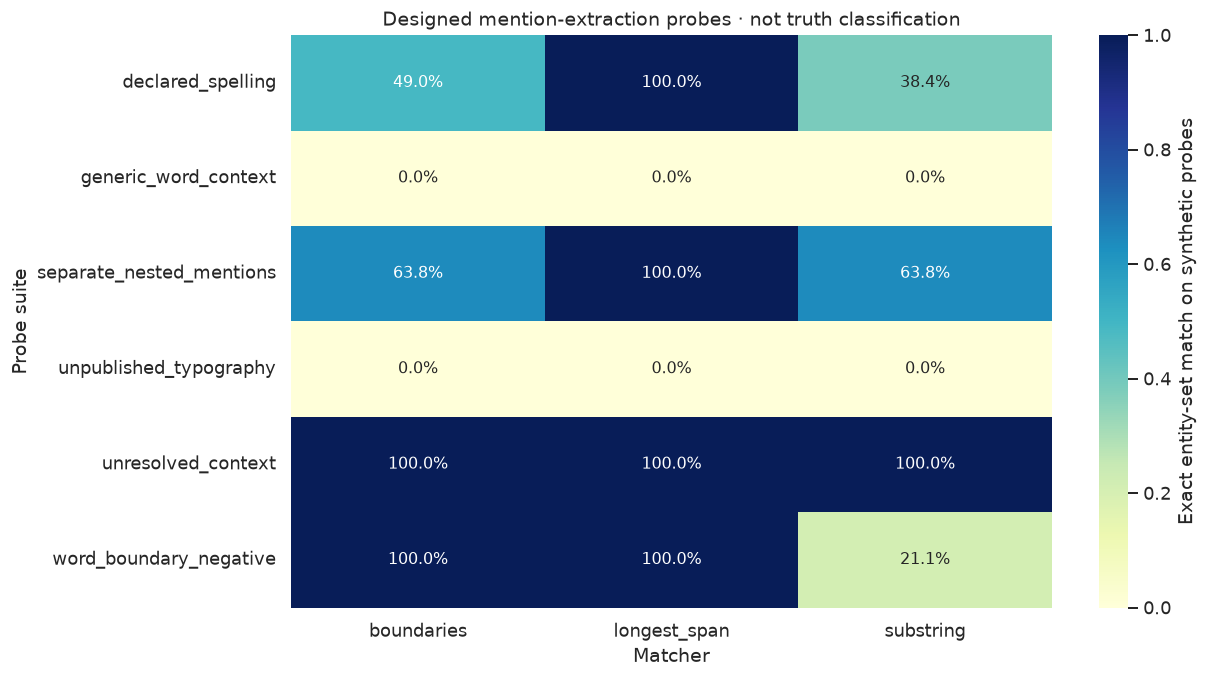

,suite,variant,text,expected,predicted
2792,generic_word_context,ordinary_word_not_entity,Search the archive for a receipt.,[],[Hooly Search]
2795,generic_word_context,ordinary_word_not_entity,Translate the sentence into French.,[],[Hooly Translate]
2798,generic_word_context,ordinary_word_not_entity,Photos were attached to the letter.,[],[Hooly Photos]
2801,generic_word_context,ordinary_word_not_entity,Maps help walkers find their route.,[],[Hooly Maps]
2804,generic_word_context,ordinary_word_not_entity,There was an outage in an unrelated town.,[],[The May 2026 outage]
2816,unpublished_typography,curly_apostrophe,Hooly’s board was mentioned.,[Hooly Board],[Hooly]
2819,unpublished_typography,fullwidth_slash,Hooly I／O 2026 was mentioned.,[Hooly I/O 2026],[Hooly]


**Interpretation:** longest-span resolution addresses nested names and word boundaries on these probes. Ordinary-word ambiguity and undeclared typography remain visible failures. The unresolved-context suite checks only that the matcher does not hallucinate explicit mentions; it does not establish correct pronoun resolution. Synthetic perfect scores are not deployment guarantees.

In [24]:
accuracy = metrics.exact_match.unstack("matcher")
plt.figure(figsize=(11, 6))
sns.heatmap(accuracy, annot=True, fmt=".1%", cmap="YlGnBu", vmin=0, vmax=1,
            cbar_kws={"label": "Exact entity-set match on synthetic probes"})
plt.title("Designed mention-extraction probes · not truth classification")
plt.xlabel("Matcher"); plt.ylabel("Probe suite")
finish_figure("13_matcher_experiment")
failures = probe_results.loc[~probe_results.exact].merge(probes[["text"]], left_on="probe_id", right_index=True)
display(failures.query("matcher == 'longest_span'")[["suite", "variant", "text", "expected", "predicted"]].head(30))
designed_suites = ["declared_spelling", "word_boundary_negative", "separate_nested_mentions"]
designed = probe_results.query("matcher == 'longest_span'").loc[lambda f: f.suite.isin(designed_suites)]
assert designed.exact.all(), "The prototype fails a supported spelling/boundary/nesting case; inspect failures"
assert not probe_results.query("matcher == 'longest_span' and suite == 'generic_word_context'").exact.all(), \
    "Unexpected: review whether the ambiguity probes still exercise dictionary false positives"
display(Markdown("**Interpretation:** longest-span resolution addresses nested names and word boundaries on these probes. "
                 "Ordinary-word ambiguity and undeclared typography remain visible failures. "
                 "The unresolved-context suite checks only that the matcher does not hallucinate explicit mentions; "
                 "it does not establish correct pronoun resolution. Synthetic perfect scores are not deployment guarantees."))

### Slot validation and attribute discrimination

Once an entity is resolved, its attribute list is a useful **constraint**, not a prediction.
We generate valid slot references and invalid cross-schema substitutions. Invalid references are useful for
testing parsers and validators; they must not automatically be labelled false claims about the fictional world.

In [25]:
def is_legal_slot(subject, attribute): return attribute in subject_attributes.get(subject, set())
slot_tests = []
for row in slots.itertuples():
    slot_tests.append({"subject": row.subject, "attribute": row.attribute, "expected_legal": True, "reason": "declared pair"})
for subject in sorted(names_raw):
    invalid = sorted(set(attribute_counts.index) - subject_attributes[subject])
    for attribute in invalid[:5]:
        slot_tests.append({"subject": subject, "attribute": attribute, "expected_legal": False, "reason": "attribute belongs elsewhere"})
slot_test_frame = pd.DataFrame(slot_tests)
slot_test_frame["actual_legal"] = [is_legal_slot(r.subject, r.attribute) for r in slot_test_frame.itertuples()]
assert (slot_test_frame.expected_legal == slot_test_frame.actual_legal).all()
display(slot_test_frame.groupby(["reason", "expected_legal"]).size().rename("test_cases"))
display(Markdown("**Scope:** this is a schema integrity check, not evidence of extraction accuracy or fact-checking ability."))

reason                       expected_legal
attribute belongs elsewhere  False             310
declared pair                True              514
Name: test_cases, dtype: int64

**Scope:** this is a schema integrity check, not evidence of extraction accuracy or fact-checking ability.

<a id="evaluation"></a>
## 15. Synthetic-data and evaluation design

### What we can safely generate now

Mention probes and slot-validation cases have explicit expected outputs grounded in the lexicon. They can be
used as a regression suite. Do not turn arbitrary number substitutions into truth-labelled training data: a changed
value might be true at another date, unsupported, or the wrong kind altogether. The later practice study must provide
the evidence needed to produce true, false, and genuinely indeterminate cases.

### What a later truth-labelled generator must preserve

- Source row IDs and source **document grouping where recoverable**; never invent document IDs from adjacency alone.
- Entity, attribute, value kind, unit/currency/period, comparator, date precision, and temporal scope.
- Whether a label applies to a single claim or a conjunction. A false conjunction does not make every component false.
- Whether `unsure` is the dataset's state of knowledge or the system's abstention; these need separate evaluation.
- Provenance of every transformation, template ID, parent example ID, and train/validation/test membership.

Generate transformations **after** assigning original evidence to folds, keeping siblings together. Otherwise
paraphrases and mutated values leak across splits. Keep the current synthetic regression suite separate from
an untouched natural-sentence benchmark.

In [26]:
test_design = pd.DataFrame([
    ("All canonical names", "One explicit mention per subject", "Now", "Entity ID and span", "Canonical-only success hides alias failures"),
    ("Alias variants", "Case, spacing, punctuation context, possessive", "Now", "Entity ID and span", "Deduplicate normalised aliases before weighting"),
    ("Nested names", "Parent and variant alone, then both in one sentence", "Now", "Distinct spans and IDs", "Never emit nested parent from same span"),
    ("Generic aliases", "Product context vs ordinary-language context", "Manual contextual annotation", "Entity sense or abstention", "Dictionary hit is not sufficient"),
    ("Rare attributes", "At least one example per legal slot", "After practice analysis", "Entity + attribute + value", "Singleton attributes need macro reporting"),
    ("Near attributes", "Storage vs upload limit; version vs history", "After practice analysis", "Correct scoped attribute", "Shared tokens are not semantic equivalence"),
    ("Units and periods", "Convertible units; monthly vs annual vs one-off", "After practice analysis", "Normalised value with dimensions", "Same numeric value need not mean same claim"),
    ("Time boundaries", "Before/on/after verified change dates", "After practice analysis", "Dated truth label", "Latest evidence is not timeless truth"),
    ("Events", "Each declared event, including missing date slots", "After practice analysis", "Resolved event date or uncertainty", "Year in event name is not its day"),
    ("Relations", "Link changes and target facts at overlapping dates", "After practice analysis", "Supported multi-step derivation", "No link target can be inferred from this lexicon"),
    ("Multi-claim rows", "One false component; one unknown; all true", "After practice analysis", "Sentence label with component evidence", "Do not copy row label onto every fact"),
    ("Unseen surface style", "Held-out documents and paraphrase templates", "After practice analysis", "Extraction and truth metrics", "Random row splits can leak templates")
], columns=["stratum", "generation_plan", "when", "expected_output", "failure_to_avoid"])
show_all(test_design)

evaluation_plan = pd.DataFrame([
    ("Entity resolution", "Span precision/recall/F1; exact entity-set match", "Canonical, alias, nesting, generic-word context"),
    ("Attribute extraction", "Micro and macro exact match; coverage", "Subject, attribute frequency, family, multi-claim rows"),
    ("Value parsing", "Exact structured match and dimension errors", "Kind, unit, period, comparator, date precision"),
    ("Truth classification", "Per-label confusion matrix and macro F1", "Date ranges, known vs unknown evidence, contradictions"),
    ("Confidence", "Reliability plots, Brier score when probabilities are defined", "Correctness of emitted label; abstention separately"),
    ("Selective prediction", "Accuracy/error vs answered fraction", "Separate epistemic unknowns from low-confidence extraction"),
    ("Claim generation", "Schema + text validity, supported truth, novelty, unique forms", "Each claim type; target exactly 1,000 valid claims"),
    ("Runtime", "End-to-end wall time, peak memory, output completeness", "Offline 2-CPU/6-GiB constraints and deadline handling")
], columns=["layer", "metrics", "report_slices"])
display(evaluation_plan)

,stratum,generation_plan,when,expected_output,failure_to_avoid
0,All canonical names,One explicit mention per subject,Now,Entity ID and span,Canonical-only success hides alias failures
1,Alias variants,"Case, spacing, punctuation context, possessive",Now,Entity ID and span,Deduplicate normalised aliases before weighting
2,Nested names,"Parent and variant alone, then both in one sentence",Now,Distinct spans and IDs,Never emit nested parent from same span
3,Generic aliases,Product context vs ordinary-language context,Manual contextual annotation,Entity sense or abstention,Dictionary hit is not sufficient
4,Rare attributes,At least one example per legal slot,After practice analysis,Entity + attribute + value,Singleton attributes need macro reporting
5,Near attributes,Storage vs upload limit; version vs history,After practice analysis,Correct scoped attribute,Shared tokens are not semantic equivalence
6,Units and periods,Convertible units; monthly vs annual vs one-off,After practice analysis,Normalised value with dimensions,Same numeric value need not mean same claim
7,Time boundaries,Before/on/after verified change dates,After practice analysis,Dated truth label,Latest evidence is not timeless truth
8,Events,"Each declared event, including missing date slots",After practice analysis,Resolved event date or uncertainty,Year in event name is not its day
9,Relations,Link changes and target facts at overlapping dates,After practice analysis,Supported multi-step derivation,No link target can be inferred from this lexicon


,layer,metrics,report_slices
0,Entity resolution,Span precision/recall/F1; exact entity-set match,"Canonical, alias, nesting, generic-word context"
1,Attribute extraction,Micro and macro exact match; coverage,"Subject, attribute frequency, family, multi-claim rows"
2,Value parsing,Exact structured match and dimension errors,"Kind, unit, period, comparator, date precision"
3,Truth classification,Per-label confusion matrix and macro F1,"Date ranges, known vs unknown evidence, contradictions"
4,Confidence,"Reliability plots, Brier score when probabilities are defined",Correctness of emitted label; abstention separately
5,Selective prediction,Accuracy/error vs answered fraction,Separate epistemic unknowns from low-confidence extraction
6,Claim generation,"Schema + text validity, supported truth, novelty, unique forms","Each claim type; target exactly 1,000 valid claims"
7,Runtime,"End-to-end wall time, peak memory, output completeness",Offline 2-CPU/6-GiB constraints and deadline handling


### A reproducible coverage budget, not an estimate of corpus prevalence

If we allocate an equal number of future examples per legal slot, what does the workload look like?
The calculator below exposes the trade-off. It does not manufacture truth labels or assume all slots are observed.
Any unsupported slot should stay in a coverage-gap report rather than receive invented evidence.

In [27]:
EXAMPLES_PER_SLOT = 6  # Adjust for planning only.
coverage_budget = subjects[["subject", "attribute_count", "family_hypothesis"]].copy()
coverage_budget["planned_examples"] = coverage_budget.attribute_count * EXAMPLES_PER_SLOT
display(coverage_budget.groupby("family_hypothesis").agg(slots=("attribute_count", "sum"), planned_examples=("planned_examples", "sum")))
display(Markdown(f"At **{EXAMPLES_PER_SLOT}** examples per declared slot, the proposed budget is "
                 f"**{coverage_budget.planned_examples.sum():,}** examples. This is a design target, not available evidence."))
split_plan = pd.DataFrame([
    ("Document/group holdout", "Keep all rows and transformations from one source group together", "Generalisation to new writing contexts"),
    ("Template holdout", "Hold out paraphrase patterns and their generated siblings", "Avoid learning only surface templates"),
    ("Temporal holdout", "Train/seed on earlier evidence and evaluate later dates", "Measure the cost of unknown changes, not guaranteed future truth"),
    ("Family stress holdout", "Hold out reviewed sibling families together", "Measure schema transfer; this is harder than the official mixed-universe task"),
    ("Official-like transductive run", "Expose all allowed input rows, retain only permitted seed labels", "Closest runtime setting; do not accidentally bake hidden labels into evaluation")
], columns=["split", "grouping_rule", "purpose"])
display(split_plan)

,slots,planned_examples
family_hypothesis,,
declared event,113,678
device (hypothesis),62,372
external organisation (hypothesis),2,12
office (hypothesis),15,90
organisation / programme (hypothesis),66,396
person (hypothesis),16,96
plan / suite (hypothesis),43,258
software / service (hypothesis),195,1170
venue (hypothesis),2,12


At **6** examples per declared slot, the proposed budget is **3,084** examples. This is a design target, not available evidence.

,split,grouping_rule,purpose
0,Document/group holdout,Keep all rows and transformations from one source group together,Generalisation to new writing contexts
1,Template holdout,Hold out paraphrase patterns and their generated siblings,Avoid learning only surface templates
2,Temporal holdout,Train/seed on earlier evidence and evaluate later dates,"Measure the cost of unknown changes, not guaranteed future truth"
3,Family stress holdout,Hold out reviewed sibling families together,Measure schema transfer; this is harder than the official mixed-universe task
4,Official-like transductive run,"Expose all allowed input rows, retain only permitted seed labels",Closest runtime setting; do not accidentally bake hidden labels into evaluation


<a id="findings"></a>
## 16. Prioritised findings and open questions

This section ties measurements to implementation decisions and falsifiable follow-up questions.
Priorities are an analyst judgement, not a competition scoring formula.

In [28]:
findings = pd.DataFrame([
    ("P0", "Measured", f"{N} subjects; {len(slots)} legal slots; {len(attribute_counts)} distinct attributes", "Use canonical (subject, attribute) keys", "How many legal slots have labelled evidence?"),
    ("P0", "Measured", f"{len(overlap_pairs)} directed whole-word entity containment pairs", "Resolve spans before emitting entities", "How often do nested names occur in practice sentences?"),
    ("P0", "Measured", f"{int((~event_audit.has_date_attribute).sum())} events lack a date attribute", "Keep event-date resolution as an explicit dependency", "Can practice provide an unambiguous event date?"),
    ("P0", "Measured", "No values, units, intervals or truth labels in lexicon", "Do not promote schema entries into facts", "Which types/units/cardinalities are actually observed?"),
    ("P1", "Measured", f"{int(attribute_inventory.is_singleton.sum())} attributes occur on only one subject", "Audit per-slot coverage; report macro metrics", "Do rare attributes also have few training sentences?"),
    ("P1", "Measured", "Normalisation can produce redundant aliases", "Deduplicate lookup keys while preserving source records", "Do case variants affect corpus matching?"),
    ("P1", "Experiment", "Longest-span rules solve designed nesting probes but not generic-word senses", "Add context-sensitive candidate selection", "Which contextual features distinguish product mentions?"),
    ("P1", "Measured", "Some subjects have identical attribute schemas", "Retain entity identity independently of schema similarity", "Are sibling products confused in extracted forms?"),
    ("P1", "Hypothesis", "Role/place identifiers may support relational claims", "Learn target kinds and validity from evidence", "Which links resolve to declared subjects with usable facts?"),
    ("P2", "Hypothesis", "Schema neighbourhoods can organise augmentation and holdouts", "Review families; test threshold sensitivity", "Do families transfer extraction patterns without leaking values?")
], columns=["priority", "evidence", "finding", "design_implication", "next_question"])
show_all(findings)

,priority,evidence,finding,design_implication,next_question
0,P0,Measured,62 subjects; 514 legal slots; 321 distinct attributes,"Use canonical (subject, attribute) keys",How many legal slots have labelled evidence?
1,P0,Measured,58 directed whole-word entity containment pairs,Resolve spans before emitting entities,How often do nested names occur in practice sentences?
2,P0,Measured,6 events lack a date attribute,Keep event-date resolution as an explicit dependency,Can practice provide an unambiguous event date?
3,P0,Measured,"No values, units, intervals or truth labels in lexicon",Do not promote schema entries into facts,Which types/units/cardinalities are actually observed?
4,P1,Measured,241 attributes occur on only one subject,Audit per-slot coverage; report macro metrics,Do rare attributes also have few training sentences?
5,P1,Measured,Normalisation can produce redundant aliases,Deduplicate lookup keys while preserving source records,Do case variants affect corpus matching?
6,P1,Experiment,Longest-span rules solve designed nesting probes but not generic-word senses,Add context-sensitive candidate selection,Which contextual features distinguish product mentions?
7,P1,Measured,Some subjects have identical attribute schemas,Retain entity identity independently of schema similarity,Are sibling products confused in extracted forms?
8,P1,Hypothesis,Role/place identifiers may support relational claims,Learn target kinds and validity from evidence,Which links resolve to declared subjects with usable facts?
9,P2,Hypothesis,Schema neighbourhoods can organise augmentation and holdouts,Review families; test threshold sensitivity,Do families transfer extraction patterns without leaking values?


### Questions reserved for the practice-data notebook

1. **Coverage:** join every annotated form to these slots; report missing subjects, invalid attributes,
   undeclared name-valued targets, and slots with no labelled evidence.
2. **Type inventory:** observe all `(kind, unit, currency, per, op)` signatures per slot, preserving original
   value forms and date precision. Investigate conflicts instead of coercing them away.
3. **Time:** distinguish document date from dates asserted in text, compare values over time, and locate
   supported changes without assuming continuity between observations.
4. **Sentence structure:** measure pronouns, explicit names, fragments, multi-fact rows, aliases actually used,
   and potential document boundaries. Verify ordering before using neighbouring sentences as context.
5. **Labels:** examine `true`, `false`, and `unsure` by subject, attribute, time, and claim count. A row-level false
   label supplies a constraint over its component claims, not an independent negative label for each component.
6. **Leakage:** inspect exact/near duplicates, repeated templates, shared source documents, and temporal echoes
   before selecting a meaningful holdout.
7. **Generation:** count genuinely supported comparisons, historical transitions, event-time facts, and
   temporally valid relation chains. Rank by evidence quality, not by the size of the raw candidate space.
8. **Uncertainty:** distinguish missing evidence, conflicting evidence, parser failure, and true dataset-level
   indeterminacy. Do not merge these into a single unexplained `unsure` bucket during analysis.

**Working conclusion:** the lexicon is a strong constraint system and a useful test generator. It is not a
truth database. The safest next layer is evidence-aware extraction, with explicit provenance and time handling.

<a id="exports"></a>
## 17. Exports and integrity checks

All complete tables are exported, including those displayed only as previews. Nested cells are serialised as
JSON strings in CSV. The canonical indexes contain only lexicon declarations; type and family suggestions are
kept in explicitly named hypothesis exports. The synthetic probe manifest records expected **entity IDs**,
not truth labels. The output manifest fingerprints inputs and generated artifacts so later notebooks can detect drift.

In [29]:
tables = {
    "validation": validation, "summary": summary, "subjects": subjects, "surfaces": surfaces,
    "slots": slots, "missingness": missingness, "normalisation_audit": normalisation_audit,
    "normalisation_redundancies": redundancies, "name_overlaps": overlaps, "near_name_pairs": near_names,
    "attribute_inventory": attribute_inventory, "attribute_tokens": token_stats.reset_index(),
    "confusable_attribute_review": confusable_attributes, "incidence": incidence.reset_index(),
    "schema_components": components, "identical_schemas": identical_schemas,
    "subject_similarities": similarities, "similarity_threshold_sensitivity": threshold_sensitivity,
    "family_hypothesis_summary": family_summary.reset_index(), "attribute_cooccurrence": cooccurrence,
    "identical_attribute_support": same_support, "event_audit": event_audit, "temporal_slot_candidates": temporal_slots,
    "type_hypotheses": type_hypotheses, "relation_candidates": relation_candidates,
    "ambiguous_type_review": ambiguous_type_review, "comparison_candidates": comparison_candidates,
    "claim_candidate_spaces": candidate_spaces, "claim_evidence_requirements": contract_matrix,
    "entity_probes": probes, "entity_probe_results": probe_results, "entity_probe_metrics": metrics.reset_index(),
    "entity_probe_failures": failures, "slot_validation_probes": slot_test_frame,
    "synthetic_data_design": test_design, "evaluation_plan": evaluation_plan,
    "coverage_budget": coverage_budget, "split_plan": split_plan, "prioritised_findings": findings,
}
def csv_ready(frame):
    frame = frame.copy()
    for col in frame.columns:
        frame[col] = frame[col].map(lambda value: json.dumps(value, ensure_ascii=False, sort_keys=True)
                                  if isinstance(value, (list, dict, tuple)) else value)
    return frame

for name, table in tables.items():
    csv_ready(table).to_csv(TABLES / f"{name}.csv", index=False)
surface_index = unique_surfaces.groupby("normalised").subject.agg(lambda x: sorted(set(x))).to_dict()
canonical_index = {"source_sha256": source_sha256,
    "normalisation": "NFKC, casefold, collapse whitespace; punctuation preserved",
    "surface_to_subjects": surface_index,
    "subject_to_attributes": {k: sorted(v) for k, v in subject_attributes.items()},
    "attribute_to_subjects": attribute_subjects, "events": sorted(event_names)}
(OUTPUT / "canonical_indexes.json").write_text(json.dumps(canonical_index, indent=2, ensure_ascii=False) + "\n")
(OUTPUT / "synthetic_entity_probes.json").write_text(probes.to_json(orient="records", indent=2, force_ascii=False) + "\n")

assert raw_path.read_bytes() == raw_bytes, "Source was modified"
assert set(canonical_index["subject_to_attributes"]) == set(names_raw)
assert sum(map(len, canonical_index["subject_to_attributes"].values())) == len(slots)
assert set(event_names) <= set(names_raw)
assert len(type_hypotheses) == len(attribute_counts)
assert all((TABLES / f"{name}.csv").is_file() for name in tables)
assert len(probe_results) == len(probes) * len(matchers)
for name in tables:
    restored = pd.read_csv(TABLES / f"{name}.csv")
    assert len(restored) == len(tables[name]), f"Export row-count mismatch: {name}"

artifact_paths = sorted([*(TABLES / f"{name}.csv" for name in tables),
    *(FIGURES / f"{name}.{extension}" for name in figure_names for extension in ["png", "pdf"]),
    OUTPUT / "canonical_indexes.json", OUTPUT / "synthetic_entity_probes.json"])
contract_files = [ROOT / "contracts" / name for name in ["README.md", "claim-forms.md", "value-forms.md", "entry.schema.json", "claimed_value.schema.json"]]
manifest = {"source": "data/lexicon.json", "source_sha256": source_sha256,
    "contract_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in contract_files},
    "python": platform.python_version(), "packages": environment, "seed": SEED,
    "scope": "Lexicon only; practice.csv was not loaded. Hypotheses and synthetic probes are not truth labels.",
    "tables": {name: len(table) for name, table in tables.items()},
    "figures": figure_names,
    "artifacts": {str(p.relative_to(OUTPUT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in artifact_paths}}
(OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False) + "\n")
display(Markdown(f"Exported **{len(tables)} complete tables**, **{len(figure_names)} figures** in PNG and PDF, "
                 f"canonical indexes, **{len(probes):,}** synthetic mention probes, and a provenance manifest. "
                 "All integrity and export round-trip row-count checks passed."))

Exported **39 complete tables**, **13 figures** in PNG and PDF, canonical indexes, **940** synthetic mention probes, and a provenance manifest. All integrity and export round-trip row-count checks passed.

<a id="atlas"></a>
## 18. Complete subject and attribute atlas

No top-N truncation in this appendix. Use the exported CSVs for sorting/filtering outside Jupyter.
Family and type suggestions remain labelled hypotheses. Alias spellings are preserved exactly as supplied.

In [30]:
atlas = subjects[["subject", "is_event", "family_hypothesis", "aliases", "attribute_count", "attributes"]].copy()
show_all(atlas)

,subject,is_event,family_hypothesis,aliases,attribute_count,attributes
0,Bertram Gilfoil,False,person (hypothesis),[],2,"[joined, previous_employer]"
1,Brightline Labs,False,external organisation (hypothesis),[Brightline],1,[integration_partner_of_flawless]
2,Dinesh Chugtay,False,person (hypothesis),[],1,[joined]
3,Erlich Bachmann,False,person (hypothesis),[],1,[joined]
4,Gemini Launch Night,True,declared event,[Launch Night],3,"[attendees, city, date]"
5,Holdan,False,person (hypothesis),[],3,"[joined, previous_employer, team_size]"
6,Hooly,False,organisation / programme (hypothesis),"[Hooly AI, Hooly Inc.]",32,"[annual_recurring_revenue, ceo, cto, customer_countries, customers_in_the_eu, data_processing_agreement, employees, founded, founders, fully_remote, had_major_outage, head_of_product, head_of_security, head_of_workspace, headquarters, help_guides, incidents_this_year, net_promoter_score, newsletter_subscribers, offices, paying_customers, raised_series_a, raised_series_b, series_a_amount, series_a_co_investor, series_a_lead, soc2_audit_start, soc2_auditor, soc2_certified, support_satisfaction, support_tickets_per_week, webinars_held]"
7,Hooly AI Free,False,plan / suite (hypothesis),[],4,"[daily_requests, history_retention, max_upload_size, price]"
8,Hooly AI Pro,False,plan / suite (hypothesis),[],9,"[annual_price, free_trial, history_retention, included_seats, price, refund_window, saved_projects, signed_in_devices, support_first_response]"
9,Hooly Android,False,software / service (hypothesis),[Android],4,"[active_devices, lead, open_source, version]"


In [31]:
full_attribute_atlas = attribute_inventory[["attribute", "subject_count", "subjects"]].merge(
    type_hypotheses[["attribute", "candidate_kinds", "status"]], on="attribute", validate="one_to_one")
show_all(full_attribute_atlas.sort_values("attribute").reset_index(drop=True))

,attribute,subject_count,subjects,candidate_kinds,status
0,active_devices,1,[Hooly Android],[quantity],single hypothesis; unverified
1,active_users,6,"[Hooly Calendar, Hooly Docs, Hooly Drive, Hooly Gmail, Hooly Meet, Hooly Sheets]",[quantity],single hypothesis; unverified
2,ad_free_option,1,[Hooly Search],[boolean],single hypothesis; unverified
3,ad_free_price,1,[Hooly Search],[money],single hypothesis; unverified
4,adaptive_noise_cancelling,1,[Hooly Pixel Buds],[boolean],single hypothesis; unverified
5,advertising_share,4,"[Hooly Q1 2026 Results, Hooly Q2 2026 Results, Hooly Q3 2026 Results, Hooly Q4 2025 Results]",[percent],single hypothesis; unverified
6,ai_answers,1,[Hooly Search],[boolean],single hypothesis; unverified
7,ai_editing,1,[Hooly Photos],[boolean],single hypothesis; unverified
8,ai_sidebar,1,[Hooly Chrome],[boolean],single hypothesis; unverified
9,announced,3,"[Hooly Lisbon Office, Hooly Maps Day, Hooly Vault]",[date],single hypothesis; unverified


### Reading and rerunning the deliverable

- **Notebook:** `analysis/01_lexicon_analysis.ipynb` — executable source, narrative, figures, and outputs.
- **HTML:** `analysis/01_lexicon_analysis.html` — saved rendered version for reading without Jupyter.
- **Tables and figures:** `analysis/lexicon_outputs/` — reusable analysis artifacts.
- **Environment:** `analysis/requirements-lexicon.txt` — versions used for the delivered analysis.

To rerun and refresh the HTML from the repository root:

```bash
python -m pip install -r analysis/requirements-lexicon.txt
jupyter nbconvert --to notebook --execute --inplace analysis/01_lexicon_analysis.ipynb
jupyter nbconvert --to html analysis/01_lexicon_analysis.ipynb
```

This notebook does not implement the competition system and does not analyse `practice.csv`.
Its outputs provide the audited vocabulary, explicit blind spots, and experimental foundation for that next stage.